<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase16_cnn_rnn_a_fondo_PROFE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIC 2026 · Inteligencia Artificial
## Clase 16: Redes convolucionales y recurrentes a fondo (Capítulo 9, Unidades 1 y 2)

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

En la Clase 15 entrenamos una CNN y redes recurrentes. Hoy vamos **más adentro**: qué ve realmente una CNN, cómo mejorarla, y qué pasa con una LSTM cuando por fin tiene muchos datos.

| Hora | Parte | Láminas | Qué vamos a hacer |
|---|---|---|---|
| 18:00 a 18:50 | 1. Qué ve una CNN | 5 a 36 | Filtros a mano, stride y padding, y los filtros que aprende una red |
| 18:50 a 20:00 | 2. Mejorar una CNN | 37 a 69 | CIFAR-10: de 70% hacia arriba, cambio por cambio |
| 20:00 a 20:10 | Pausa | | |
| 20:10 a 21:50 | 3. RNN con muchos datos | 70 a 80 | 25.000 reseñas de películas: LSTM, bidireccional y apilada |
| 21:50 a 22:00 | Cierre | | |

**Antes de empezar:** *Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)*. Sin GPU, las Partes 2 y 3 tardan mucho.

Hay 12 ejercicios con verificación; las soluciones están al final.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import time, warnings
warnings.filterwarnings("ignore")

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "no")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# Parte 1. Qué ve una CNN (láminas 5 a 36)

## Paso 1.1. Un filtro, a mano

Una convolución desliza un **filtro** (una pequeña matriz de pesos) sobre la imagen. En cada posición multiplica el filtro por la zona que cubre, posición por posición, y suma. Si la zona se parece al patrón del filtro, el resultado es alto.

**Qué vamos a hacer:** aplicar a mano un filtro que detecta **bordes verticales** sobre un trozo de 3 × 3.

In [ ]:
zona = np.array([[10, 10, 200],
                 [10, 10, 200],
                 [10, 10, 200]])          # oscuro a la izquierda, claro a la derecha: un borde vertical

filtro_vertical = np.array([[-1, 0, 1],
                            [-1, 0, 1],
                            [-1, 0, 1]])  # resta la izquierda y suma la derecha

producto = zona * filtro_vertical         # multiplicación posición por posición
print("Producto:\n", producto)
print("Suma (el valor del mapa en esta posición):", producto.sum())

Producto:
 [[-10   0 200]
 [-10   0 200]
 [-10   0 200]]
Suma (el valor del mapa en esta posición): 570


**Qué deberías ver:** una suma de **570**: el filtro "se enciende" porque encontró un cambio de oscuro a claro. Sobre una zona pareja (todos 10), daría 0.

### Ejercicio 1
Aplica el mismo `filtro_vertical` a `zona_pareja` (una zona de color uniforme) y guarda el resultado en `valor_pareja`. Luego aplica el filtro de **bordes horizontales** (la transpuesta del vertical, `filtro_vertical.T`) a la `zona` original y guárdalo en `valor_horizontal`.

In [ ]:
zona_pareja = np.full((3, 3), 120)

valor_pareja = None       # TU CÓDIGO AQUÍ
valor_horizontal = None   # TU CÓDIGO AQUÍ
print(valor_pareja, valor_horizontal)

None None


In [ ]:
revisar(lambda: valor_pareja == 0 and valor_horizontal == 0)

Todavía no. Revisa tu respuesta.


**Por qué los dos dan 0:** en una zona pareja no hay bordes; y el borde de `zona` es **vertical**, así que el filtro horizontal no lo detecta. Cada filtro busca un patrón distinto.

## Paso 1.2. Filtros sobre una foto real

**Qué vamos a hacer:** aplicar tres filtros clásicos a una foto completa (incluida en scikit-learn). `tf.nn.conv2d` hace la misma cuenta del Paso 1.1, en todas las posiciones a la vez.

## Coding Exercise #0701

### 1. Convolutional Neural Network(MNIST):

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
# Install tensorflow_datasets.
!pip install tensorflow_datasets

In [ ]:
import tensorflow_datasets as tfds
import numpy as np

In [ ]:
# Hyperparameter definitions.
BUFFER_SIZE = 10000
BATCH_SIZE = 64
NUM_EPOCHS = 20

In [ ]:
# Calculate the number of steps per epoch (60,000 images total).
steps_per_epoch = int(np.ceil(60000 / BATCH_SIZE))

In [ ]:
# Install missing dependency and load MNIST dataset.
!pip install importlib_resources

(ds_train, ds_test), ds_info = tfds.load(
    'mnist',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist/incomplete.RPOIG8_3.0.1/mnist-train.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist/incomplete.RPOIG8_3.0.1/mnist-test.tfrecord-[0-9][0-9][0-9][0-9][0-9…

Dataset mnist downloaded and prepared to /root/tensorflow_datasets/mnist/3.0.1. Subsequent calls will reuse this data.


In [ ]:
# Preprocessing function.
def preprocess(image, label):
    image = tf.image.convert_image_dtype(image, tf.float32)
    return image, label

In [ ]:
# Build input pipeline.
# Training dataset
train_ds = (
    ds_train
    .map(preprocess)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Test dataset.
test_ds = (
    ds_test
    .map(preprocess)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

`tf.keras.layers.Flatten()` **aplana** la entrada: convierte un tensor multidimensional en un vector de una sola dimensión por cada ejemplo, sin modificar los datos ni agregar parámetros entrenables.

Por ejemplo, si cada imagen de entrada mide 28×28 píxeles (como en MNIST), `Flatten` la transforma en un vector de 784 valores (28 × 28). La dimensión del batch se conserva: un tensor de forma `(batch, 28, 28)` pasa a ser `(batch, 784)`.

Se usa porque las capas `Dense` esperan vectores planos como entrada. Por eso suele ir al comienzo de un modelo simple que recibe imágenes, o entre las capas convolucionales y las densas en una CNN:

```python
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),  # (28,28) -> (784,)
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
```

Una consecuencia de aplanar es que se pierde la estructura espacial: la red ya no "sabe" qué píxeles eran vecinos. Para imágenes, esto se compensa usando capas convolucionales antes del `Flatten`, o reemplazándolo por `GlobalAveragePooling2D`, que reduce la dimensión con muchos menos parámetros en la capa densa siguiente.

In [ ]:
# Tomamos una imagen de ejemplo del dataset de Fashion MNIST o MNIST que ya tenemos cargado
ejemplo_mnist = Xf_tr[0] # Forma original: (28, 28, 1)

# Quitamos el canal extra para tener la matriz de 28x28
matriz_28x28 = ejemplo_mnist.reshape(28, 28)
print("1. Forma original de la imagen:", matriz_28x28.shape)

# Aplicamos flatten para aplanar la imagen
vector_aplanado = matriz_28x28.flatten()
print("2. Forma después de aplicar flatten():", vector_aplanado.shape)
print("\nPrimeros 20 valores del vector aplanado:\n", vector_aplanado[:20])

1. Forma original de la imagen: (28, 28)
2. Forma después de aplicar flatten(): (784,)

Primeros 20 valores del vector aplanado:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
# Define the DNN classifier model.
dnn_classifier = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model.
dnn_classifier.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Más que una neurona, esto es una **red neuronal completa** (una DNN, *deep neural network*) con varias capas, cada una formada por muchas neuronas. Es un clasificador de imágenes de 28×28 píxeles en escala de grises con 10 clases posibles, que es exactamente el formato de MNIST (dígitos escritos a mano) o Fashion-MNIST (prendas de ropa).

## Recorrido capa por capa

**`tf.keras.Input(shape=(28, 28, 1))`**
Declara la forma de cada ejemplo de entrada: una imagen de 28 de alto, 28 de ancho y 1 canal (escala de grises; una imagen a color tendría 3). No es una capa que haga cálculos, solo le dice al modelo qué esperar. Keras agrega por su cuenta la dimensión del batch, así que el tensor real es `(batch, 28, 28, 1)`.

**`Flatten()`**
Convierte cada imagen en un vector de 28 × 28 × 1 = **784 valores**. Es necesario porque las capas `Dense` que vienen después solo aceptan vectores. No tiene parámetros entrenables.

**`Dense(32, activation='relu')`**
Primera capa oculta, con 32 neuronas. Cada neurona está conectada a los 784 valores de entrada y calcula:

$$z = w_1x_1 + w_2x_2 + \dots + w_{784}x_{784} + b$$

y luego aplica ReLU: $\text{ReLU}(z) = \max(0, z)$, que deja pasar los valores positivos y convierte los negativos en cero. Esa no linealidad es lo que permite a la red aprender patrones más complejos que una simple combinación lineal. Cada neurona termina especializándose en detectar algún patrón de píxeles (trazos, curvas, zonas oscuras). Salida: un vector de 32 valores.

**`Dense(16, activation='relu')`**
Segunda capa oculta, con 16 neuronas, cada una conectada a las 32 salidas anteriores. Combina los patrones simples de la capa previa en patrones más abstractos. La forma de embudo (784 → 32 → 16) obliga a la red a comprimir la información y quedarse con lo relevante para clasificar.

**`Dense(10, activation='softmax')`**
Capa de salida, con una neurona por clase. Softmax transforma los 10 valores en probabilidades que suman 1:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{10} e^{z_j}}$$

Por ejemplo, la salida podría ser `[0.01, 0.02, 0.90, ...]`, que se interpreta como "90 % de probabilidad de que sea la clase 2". La predicción final es la clase con mayor probabilidad (`argmax`).

## Formas y parámetros

| Capa | Forma de salida | Parámetros |
|---|---|---|
| Input | (28, 28, 1) | 0 |
| Flatten | (784) | 0 |
| Dense 32 | (32) | 784 × 32 + 32 = 25.120 |
| Dense 16 | (16) | 32 × 16 + 16 = 528 |
| Dense 10 | (10) | 16 × 10 + 10 = 170 |
| **Total** | | **25.818** |

En cada capa densa, los parámetros son *(entradas × neuronas)* pesos más *neuronas* sesgos. Se puede verificar con `dnn_classifier.summary()`. Casi el 97 % de los parámetros está en la primera capa densa, porque es la que recibe los 784 píxeles.

## Qué falta para que funcione

Este código solo define la arquitectura; los pesos parten aleatorios. Para entrenarla se necesita algo como:

```python
dnn_classifier.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # etiquetas como enteros 0-9
    metrics=['accuracy']
)
dnn_classifier.fit(x_train, y_train, epochs=10, validation_split=0.1)
```

Si las etiquetas vienen en formato *one-hot* (vectores de 10), se usa `categorical_crossentropy` en vez de la versión `sparse`. También conviene normalizar los píxeles a [0, 1] dividiendo por 255.

## Limitación principal

Al aplanar la imagen, la red pierde la información de qué píxeles son vecinos: para ella, el píxel (0,0) y el (0,1) son tan independientes como el (0,0) y el (27,27). Aun así, en MNIST un modelo así suele llegar a alrededor de 97 % de precisión. Para imágenes más complejas se usan redes convolucionales (CNN), que conservan la estructura espacial con capas `Conv2D` antes del `Flatten`, y que probablemente sea lo que el notebook compara más adelante si este modelo se llama "DNN classifier".

In [ ]:
# Train the model.
dnn_classifier.fit(
    train_ds,
    epochs=NUM_EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=test_ds
)

Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.8724 - loss: 0.4407 - val_accuracy: 0.9312 - val_loss: 0.2376
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9379 - loss: 0.2125 - val_accuracy: 0.9451 - val_loss: 0.1808
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9506 - loss: 0.1689 - val_accuracy: 0.9512 - val_loss: 0.1674
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9578 - loss: 0.1422 - val_accuracy: 0.9571 - val_loss: 0.1394
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9635 - loss: 0.1231 - val_accuracy: 0.9593 - val_loss: 0.1291
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9672 - loss: 0.1073 - val_accuracy: 0.9625 - val_loss: 0.1201
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9704 - loss: 0.0969 - val_accuracy: 0.9627 - val_loss: 0.1150
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9730 - loss: 0.0886 - val_accuracy: 

In [ ]:
# Evaluate the model.
eval_loss, eval_acc = dnn_classifier.evaluate(test_ds)
print("Evaluation loss:", eval_loss)
print("Evaluation accuracy:", eval_acc)

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9681 - loss: 0.1192
Evaluation loss: 0.11923873424530029
Evaluation accuracy: 0.9681000113487244


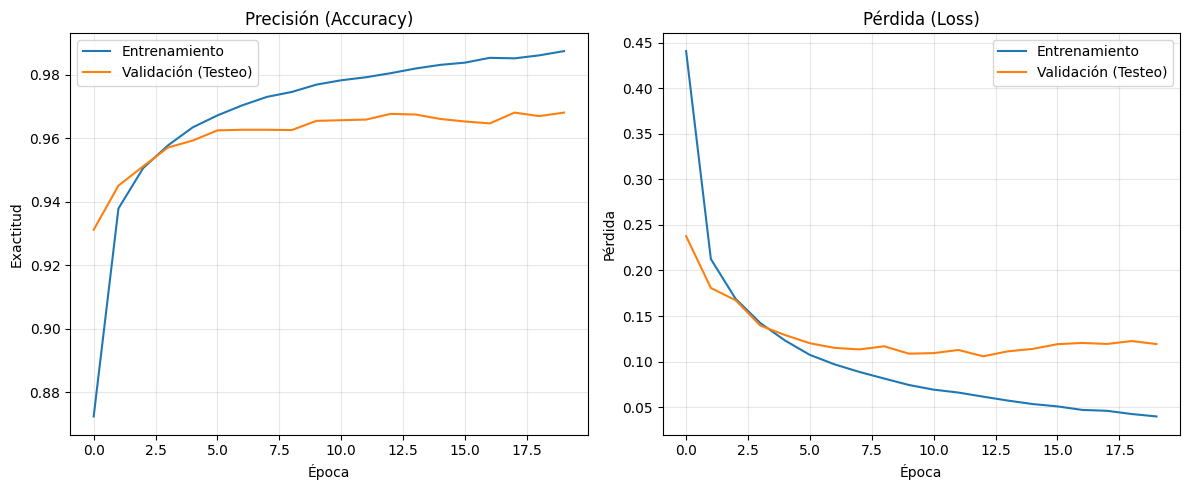

In [ ]:
import matplotlib.pyplot as plt

# Recuperamos el historial de entrenamiento del dnn_classifier
historia = dnn_classifier.history.history

# Crear gráfico de precisión (Accuracy)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(historia['accuracy'], label='Entrenamiento')
plt.plot(historia['val_accuracy'], label='Validación (Testeo)')
plt.title('Precisión (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend()
plt.grid(True, alpha=0.3)

# Crear gráfico de pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(historia['loss'], label='Entrenamiento')
plt.plot(historia['val_loss'], label='Validación (Testeo)')
plt.title('Pérdida (Loss)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q gradio

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Obtener algunas imágenes de prueba del pipeline para la interfaz interactiva
# Tomamos un lote de imágenes y etiquetas del dataset de testeo
for imgs, lbls in test_ds.take(1):
    test_images = imgs.numpy()
    test_labels = lbls.numpy()

def plot_metrics():
    hist = dnn_classifier.history.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    ax1.plot(hist['accuracy'], label='Train Acc', color='blue')
    ax1.plot(hist['val_accuracy'], label='Val Acc', color='orange')
    ax1.set_title('Exactitud (Accuracy)')
    ax1.set_xlabel('Época')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(hist['loss'], label='Train Loss', color='blue')
    ax2.plot(hist['val_loss'], label='Val Loss', color='orange')
    ax2.set_title('Pérdida (Loss)')
    ax2.set_xlabel('Época')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    return fig

def clasificar_imagen(index):
    idx = int(index)
    img = test_images[idx]
    true_label = test_labels[idx]

    # Predecir
    pred = dnn_classifier.predict(img[np.newaxis, ...], verbose=0)[0]
    class_names = [str(i) for i in range(10)]
    confidences = {class_names[i]: float(pred[i]) for i in range(10)}

    # Crear imagen para mostrar
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f"Clase Real: {true_label}")
    ax.axis('off')

    return fig, confidences

# Crear la interfaz de Gradio
with gr.Blocks() as demo:
    gr.Markdown("# 🧠 Visualizador de Impacto de Entrenamiento (DNN en MNIST)")
    gr.Markdown("Esta app te permite analizar las curvas de entrenamiento y probar el comportamiento de la red con imágenes de prueba.")

    with gr.Tab("📈 Historial de Entrenamiento"):
        btn_plot = gr.Button("Generar Gráficos de Pérdida y Exactitud")
        plot_output = gr.Plot()
        btn_plot.click(plot_metrics, outputs=plot_output)

    with gr.Tab("🔢 Clasificador Interactivo"):
        gr.Markdown("Selecciona el índice de una imagen de prueba (0 a 63) para clasificarla con la red entrenada.")
        num_input = gr.Slider(minimum=0, maximum=63, step=1, value=0, label="Índice de la imagen de prueba")
        btn_predict = gr.Button("Clasificar")

        with gr.Row():
            image_output = gr.Plot(label="Imagen MNIST")
            label_output = gr.Label(num_top_classes=3, label="Predicciones del Modelo")

        btn_predict.click(clasificar_imagen, inputs=num_input, outputs=[image_output, label_output])

demo.launch(quiet=True)

* Running on public URL: https://629643ab239e0f61cb.gradio.live


In [ ]:
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

def predecir_trazo(imagen_dict):
    # Gradio Sketchpad retorna un diccionario con la imagen dibujada en 'composite'
    if imagen_dict is None or 'composite' not in imagen_dict:
        return "Dibuja algo primero.", {}

    pil_img = imagen_dict['composite']

    # Convertir a escala de grises y cambiar tamaño a 28x28 píxeles
    gray_img = pil_img.convert('L')
    resized_img = gray_img.resize((28, 28))

    # Convertir a arreglo numpy y normalizar (escalar entre 0 y 1)
    img_array = np.array(resized_img).astype('float32') / 255.0

    # Si el fondo es blanco (255) y el trazo es oscuro, invertimos para que coincida con MNIST
    # MNIST tiene fondo negro (0) y trazo blanco (valores altos)
    if np.mean(img_array) > 0.5:
        img_array = 1.0 - img_array

    # Darle la forma que el modelo espera: (1, 28, 28, 1)
    img_input = img_array[np.newaxis, ..., np.newaxis]

    # Hacer la predicción con el dnn_classifier entrenado
    predicciones = dnn_classifier.predict(img_input, verbose=0)[0]

    # Emparejar cada número con su probabilidad
    resultado = {str(i): float(predicciones[i]) for i in range(10)}
    digito_predicho = str(np.argmax(predicciones))

    return f"Dígito detectado: {digito_predicho}", resultado

# Interfaz de dibujo interactiva usando Gradio
with gr.Blocks() as demo_dibujo:
    gr.Markdown("# 🖋️ Reconocedor de Dígitos Escritos a Mano")
    gr.Markdown("Dibuja un dígito del **0 al 9** en el recuadro negro de la izquierda y haz clic en **Clasificar** para ver la predicción en tiempo real.")

    with gr.Row():
        # Sketchpad configurado para capturar trazos (removido crop_size por incompatibilidad)
        dibujo = gr.Sketchpad(
            label="Dibuja aquí tu dígito",
            type="pil"
        )

        with gr.Column():
            texto_resultado = gr.Textbox(label="Resultado de la Predicción", interactive=False)
            grafico_probabilidades = gr.Label(num_top_classes=3, label="Probabilidades por clase")

    btn_clasificar = gr.Button("🔮 Clasificar")
    btn_clasificar.click(predecir_trazo, inputs=dibujo, outputs=[texto_resultado, grafico_probabilidades])

demo_dibujo.launch(quiet=True)

* Running on public URL: https://e7ea0f5b0cf454cb3f.gradio.live


In [ ]:
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

# Diccionario para mapear los dígitos a su nombre en inglés
DIGITS_ENGLISH = {
    0: "zero",
    1: "one",
    2: "two",
    3: "three",
    4: "four",
    5: "five",
    6: "six",
    7: "seven",
    8: "eight",
    9: "nine"
}

def procesar_y_predecir_digito(imagen_dict):
    if imagen_dict is None or 'composite' not in imagen_dict:
        return "No drawing detected"

    pil_img = imagen_dict['composite']

    # Convertir a escala de grises y redimensionar a 28x28 píxeles
    gray_img = pil_img.convert('L')
    resized_img = gray_img.resize((28, 28))

    # Convertir a arreglo numpy y normalizar a [0, 1]
    img_array = np.array(resized_img).astype('float32') / 255.0

    # Invertir colores si el fondo es blanco para coincidir con MNIST (fondo negro, trazo blanco)
    if np.mean(img_array) > 0.5:
        img_array = 1.0 - img_array

    # Preparar el tensor con forma (1, 28, 28, 1)
    img_input = img_array[np.newaxis, ..., np.newaxis]

    # Realizar la predicción usando dnn_classifier
    predicciones = dnn_classifier.predict(img_input, verbose=0)[0]
    digito_predicho = int(np.argmax(predicciones))

    return DIGITS_ENGLISH[digito_predicho]

def clasificar_dos_digitos(dibujo_izq, dibujo_der):
    resultado_izq = procesar_y_predecir_digito(dibujo_izq)
    resultado_der = procesar_y_predecir_digito(dibujo_der)

    mensaje_final = f"Left Digit: {resultado_izq.upper()}  |  Right Digit: {resultado_der.upper()}"
    return mensaje_final

# Construir la interfaz para clasificar dos dígitos uno al lado del otro
with gr.Blocks() as demo_doble:
    gr.Markdown("# 🔢 Double Handwritten Digit Recognizer (English Output)")
    gr.Markdown("Dibuja un dígito en cada uno de los recuadros de abajo y haz clic en **Classify Both** para obtener los nombres en inglés.")

    with gr.Row():
        dibujo_1 = gr.Sketchpad(label="Left Digit / Dígito Izquierdo", type="pil")
        dibujo_2 = gr.Sketchpad(label="Right Digit / Dígito Derecho", type="pil")

    with gr.Row():
        salida_texto = gr.Textbox(label="Prediction Result / Resultado en Inglés", interactive=False, text_align="center")

    btn_doble = gr.Button("🔮 Classify Both / Clasificar Ambos", variant="primary")
    btn_doble.click(
        clasificar_dos_digitos,
        inputs=[dibujo_1, dibujo_2],
        outputs=salida_texto
    )

demo_doble.launch(quiet=True)

* Running on public URL: https://a5a0c15032974594d2.gradio.live


In [ ]:
# Guardamos el dnn_classifier en el formato oficial recomendado por Keras (.keras)
dnn_classifier.save('modelo_mnist.keras')
print("¡Modelo dnn_classifier guardado exitosamente como 'modelo_mnist.keras'!")

¡Modelo dnn_classifier guardado exitosamente como 'modelo_mnist.keras'!


In [ ]:
import os
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

# Variable global para almacenar el modelo que suba el usuario
modelo_cargado = None

def cargar_modelo_subido(archivo_modelo):
    global modelo_cargado
    if archivo_modelo is None:
        return "⚠️ Por favor, sube un archivo de modelo válido."
    try:
        # Cargar el modelo desde la ruta temporal de Gradio
        modelo_cargado = tf.keras.models.load_model(archivo_modelo.name)
        return f"✅ ¡Modelo cargado exitosamente! Listo para predecir."
    except Exception as e:
        return f"❌ Error al cargar el modelo: {str(e)}"

def clasificar_con_modelo_subido(imagen_dict):
    global modelo_cargado
    if modelo_cargado is None:
        return "⚠️ Error: Primero debes subir y cargar un modelo válido.", {}

    if imagen_dict is None or 'composite' not in imagen_dict:
        return "⚠️ Dibuja un número primero.", {}

    pil_img = imagen_dict['composite']

    # Preprocesamiento idéntico al entrenamiento (MNIST)
    gray_img = pil_img.convert('L')
    resized_img = gray_img.resize((28, 28))

    img_array = np.array(resized_img).astype('float32') / 255.0
    if np.mean(img_array) > 0.5:
        img_array = 1.0 - img_array  # Invertir colores si el fondo es claro

    img_input = img_array[np.newaxis, ..., np.newaxis]

    # Predicción con el modelo cargado dinámicamente
    predicciones = modelo_cargado.predict(img_input, verbose=0)[0]

    resultado = {str(i): float(predicciones[i]) for i in range(10)}
    digito_predicho = str(np.argmax(predicciones))

    return f"Dígito detectado: {digito_predicho}", resultado

# Crear la interfaz de Gradio
with gr.Blocks() as demo_upload_predict:
    gr.Markdown("# 📂 Cargador y Clasificador de Modelos MNIST (.keras)")
    gr.Markdown("Sube tu archivo de modelo entrenado `.keras` y ponlo a prueba dibujando en el panel interactivo.")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Paso 1: Sube tu archivo `.keras`")
            archivo_input = gr.File(label="Sube el archivo 'modelo_mnist.keras'", file_types=[".keras"])
            btn_cargar = gr.Button("📥 Cargar Modelo en Memoria")
            estado_modelo = gr.Textbox(label="Estado del Modelo", value="No se ha cargado ningún modelo.", interactive=False)

        with gr.Column(scale=2):
            gr.Markdown("### Paso 2: Dibuja y clasifica")
            dibujo = gr.Sketchpad(label="Dibuja aquí tu dígito", type="pil")
            btn_predecir = gr.Button("🔮 Clasificar con Modelo Cargado", variant="primary")

            texto_resultado = gr.Textbox(label="Predicción", interactive=False)
            grafico_probabilidades = gr.Label(num_top_classes=3, label="Top 3 Probabilidades")

    # Eventos de la App
    btn_cargar.click(cargar_modelo_subido, inputs=archivo_input, outputs=estado_modelo)
    btn_predecir.click(clasificar_con_modelo_subido, inputs=dibujo, outputs=[texto_resultado, grafico_probabilidades])

demo_upload_predict.launch(quiet=True)

* Running on public URL: https://50056f29b8d9087ce1.gradio.live


## Coding Exercise #0702

### 1. Convolutional Neural Network (color images):

In [ ]:
import tensorflow as tf
print(tf.__version__)

In [ ]:
import numpy as np
import pandas as pd
from tensorflow.keras.datasets.cifar10 import load_data
import matplotlib.pyplot as plt
%matplotlib inline

#### 1.1. Download the data:

More information about the dataset can be found [here](https://www.cs.toronto.edu/~kriz/cifar.html).

In [ ]:
(X_train, y_train), (X_test, y_test) = load_data()
n_train_size = X_train.shape[0]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 677s 4us/step


#### 1.2. Take a look at the dataset:

In [ ]:
# Images already reshaped as 32x32.
# 3 Color channels.
# y is not one-hot-encoded yet.
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("\n")
print("Testing data X shape:", X_test.shape)
print("Testing data y shape:", y_test.shape)

Training data X shape: (50000, 32, 32, 3)
Training data y shape: (50000, 1)


Testing data X shape: (10000, 32, 32, 3)
Testing data y shape: (10000, 1)


Visualization.

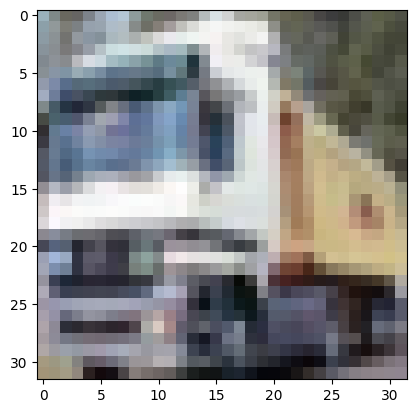

In [ ]:
i_image= 1                                                        # Image index. You can change it at will.
a_single_image= X_train[i_image, :, :, :]
plt.imshow(a_single_image)                                          #  Display as a color image.
plt.show()

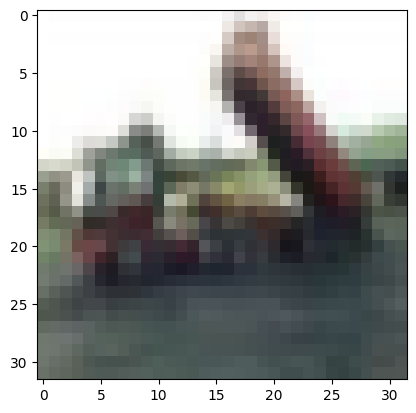

In [ ]:
i_image= 2                                                        # Image index. You can change it at will.
a_single_image= X_train[i_image, :, :, :]
plt.imshow(a_single_image)                                          #  Display as a color image.
plt.show()

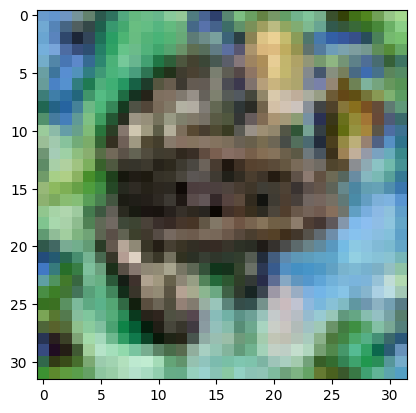

In [ ]:
i_image= 200                                                        # Image index. You can change it at will.
a_single_image= X_train[i_image, :, :, :]
plt.imshow(a_single_image)                                          #  Display as a color image.
plt.show()

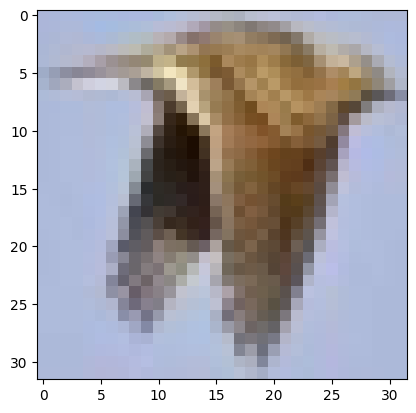

In [ ]:
i_image= 123                                                        # Image index. You can change it at will.
a_single_image= X_train[i_image, :, :, :]
plt.imshow(a_single_image)                                          #  Display as a color image.
plt.show()

In [ ]:
# Check for the minimum and maximum pixel value.
print("MIN:", a_single_image.min())
print("MAX:", a_single_image.max())

MIN: 1
MAX: 243


#### 1.3. Data preprocessing:

In [ ]:
# Scaling.
X_train = X_train / 255
X_test = X_test / 255

#### 1.4. Define the hyperparameters and placeholders:

In [ ]:
batch_size = 64
n_epochs = 20
learn_rate = 0.0001

#### 1.5. Define the deep learning model (CNN):

In [ ]:
model = tf.keras.Sequential()
model.add(tf.keras.Input(shape=(32, 32, 3)))

# 1st Convolution layer
model.add(tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(7, 7),
    strides=(1, 1),
    padding='same',
    data_format='channels_last',
    name='conv_1',
    activation=None))
# 1st Pooling layer
model.add(tf.keras.layers.MaxPool2D(
    pool_size=(2, 2),
    name='pool_1'))

In [ ]:
# 2nd Convolution layer
model.add(tf.keras.layers.Conv2D(
    filters=64,
    kernel_size=(5, 5),
    strides=(1, 1),
    padding='same',
    name='conv_2',
    activation='relu'))                      # Apply the ReLu activation function.
# 2nd Pooling layer
model.add(tf.keras.layers.MaxPool2D(
    pool_size=(2, 2),
    name='pool_2'))

In [ ]:
32*32

1024

In [ ]:
# Flattened full layer
model.add(tf.keras.layers.Flatten())
# fully connected layer
model.add(tf.keras.layers.Dense(
    units=1024,
    name='fc_1',
    activation='relu'))

In [ ]:
# Dropout layer
model.add(tf.keras.layers.Dropout(rate=0.5))

In [ ]:
# Output layer
model.add(tf.keras.layers.Dense(
    units=10,
    name='fc_2',
    activation='softmax'))

#### 1.6. Define the loss function and the optimizer:

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learn_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 32, 32, 32)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 16, 16, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_1 (Dense)                    │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_2 (Dense)                    │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,261,578 (16.26 MB)

 Trainable params: 4,261,578 (16.26 MB)

 Non-trainable params: 0 (0.00 B)

#### 1.7. Training and Testing:

In [ ]:
history = model.fit(X_train, y_train, epochs=n_epochs,
                    batch_size=batch_size,
                    validation_data=(X_test, y_test),
                    shuffle=True)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.3963 - loss: 1.6796 - val_accuracy: 0.5060 - val_loss: 1.4102
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5154 - loss: 1.3689 - val_accuracy: 0.5684 - val_loss: 1.2490
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5620 - loss: 1.2369 - val_accuracy: 0.5995 - val_loss: 1.1551
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5997 - loss: 1.1431 - val_accuracy: 0.6191 - val_loss: 1.0894
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6275 - loss: 1.0679 - val_accuracy: 0.6385 - val_loss: 1.0409
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6486 - loss: 1.0074 - val_accuracy: 0.6500 - val_loss: 1.0071
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6666 - loss: 0.9523 - val_accuracy: 0.6638 - val_loss: 0.9691
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6860 - loss: 0.9038 - val_accuracy: 

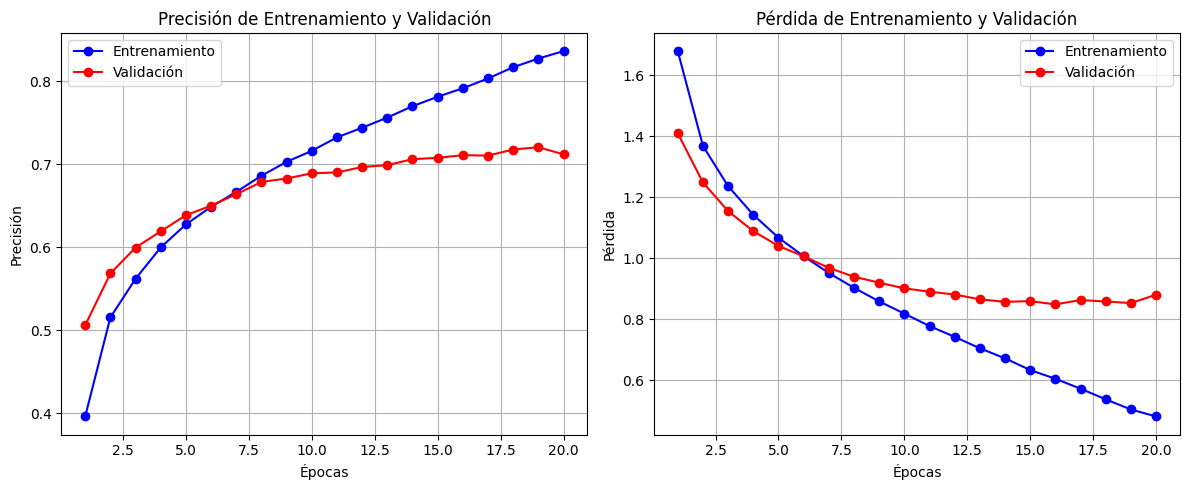

In [ ]:
import matplotlib.pyplot as plt

# Obtener los datos del historial
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Gráfico de Precisión
plt.subplot(1, 2, 1)
plt.plot(epocas, acc, 'bo-', label='Entrenamiento')
plt.plot(epocas, val_acc, 'ro-', label='Validación')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Gráfico de Pérdida
plt.subplot(1, 2, 2)
plt.plot(epocas, loss, 'bo-', label='Entrenamiento')
plt.plot(epocas, val_loss, 'ro-', label='Validación')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Guardar el modelo entrenado de CIFAR-10 en formato .keras
model.save('modelo_cifar10.keras')
print("¡Modelo CIFAR-10 guardado exitosamente como 'modelo_cifar10.keras'!")

# 2. Crear la aplicación de Gradio interactiva
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

# Definir los nombres de las clases del dataset CIFAR-10 en español
CLASES_CIFAR = ["avión", "auto", "pájaro", "gato", "ciervo", "perro", "rana", "caballo", "barco", "camión"]

# Variable para almacenar el modelo en memoria
modelo_cifar_cargado = None

def cargar_modelo_cifar(archivo_modelo):
    global modelo_cifar_cargado
    if archivo_modelo is None:
        return "⚠️ Por favor, sube un archivo de modelo .keras válido."
    try:
        modelo_cifar_cargado = tf.keras.models.load_model(archivo_modelo.name)
        return "✅ ¡Modelo CIFAR-10 cargado exitosamente en memoria! Listo para predecir."
    except Exception as e:
        return f"❌ Error al cargar el modelo: {str(e)}"

def clasificar_imagen_usuario(imagen_pil):
    global modelo_cifar_cargado
    if modelo_cifar_cargado is None:
        return "⚠️ Error: Primero debes subir y cargar un modelo válido en el Paso 1.", {}

    if imagen_pil is None:
        return "⚠️ Sube una imagen para poder realizar la clasificación.", {}

    # Preprocesamiento de la imagen:
    # Convertir a RGB (por si se sube un PNG con transparencia o escala de grises)
    img_rgb = imagen_pil.convert('RGB')
    # Redimensionar a 32x32 píxeles como requiere el modelo de CIFAR-10
    img_resized = img_rgb.resize((32, 32))
    # Normalizar los píxeles a rango [0, 1] y convertir a float32
    img_array = np.array(img_resized).astype('float32') / 255.0
    # Expandir dimensiones para cumplir con la forma de lote (1, 32, 32, 3)
    img_input = np.expand_dims(img_array, axis=0)

    # Realizar la predicción con el modelo
    predicciones = modelo_cifar_cargado.predict(img_input, verbose=0)[0]

    # Emparejar las etiquetas de clase con sus respectivas probabilidades
    probabilidades = {CLASES_CIFAR[i]: float(predicciones[i]) for i in range(10)}
    clase_ganadora = CLASES_CIFAR[np.argmax(predicciones)].upper()

    return f"Predicción del Modelo: {clase_ganadora}", probabilidades

# Construir la interfaz de usuario con Gradio
with gr.Blocks() as demo_cifar_upload:
    gr.Markdown("# 🚗🐱 Cargador y Clasificador de Imágenes CIFAR-10")
    gr.Markdown("Esta app te permite subir tu propio modelo entrenado de CIFAR-10, procesar cualquier imagen de manera automática (redimensionándola a 32x32) y clasificarla.")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Paso 1: Sube y carga tu modelo Keras")
            archivo_input = gr.File(label="Sube el archivo 'modelo_cifar10.keras'", file_types=[".keras"])
            btn_cargar = gr.Button("📥 Cargar Modelo", variant="secondary")
            estado_modelo = gr.Textbox(label="Estado de la Carga", value="No se ha cargado ningún modelo.", interactive=False)

        with gr.Column(scale=2):
            gr.Markdown("### Paso 2: Sube una foto y clasifícala")
            imagen_subida = gr.Image(label="Sube una imagen (cualquier resolución)", type="pil")
            btn_predecir = gr.Button("🔮 Clasificar Imagen", variant="primary")

            resultado_texto = gr.Textbox(label="Resultado Principal", interactive=False)
            grafico_probabilidades = gr.Label(num_top_classes=5, label="Top 5 Probabilidades")

    # Eventos de interacción de Gradio
    btn_cargar.click(cargar_modelo_cifar, inputs=archivo_input, outputs=estado_modelo)
    btn_predecir.click(clasificar_imagen_usuario, inputs=imagen_subida, outputs=[resultado_texto, grafico_probabilidades])

# Lanzar la aplicación web
demo_cifar_upload.launch(quiet=True)

¡Modelo CIFAR-10 guardado exitosamente como 'modelo_cifar10.keras'!
* Running on public URL: https://9720c0b5916285e9fe.gradio.live


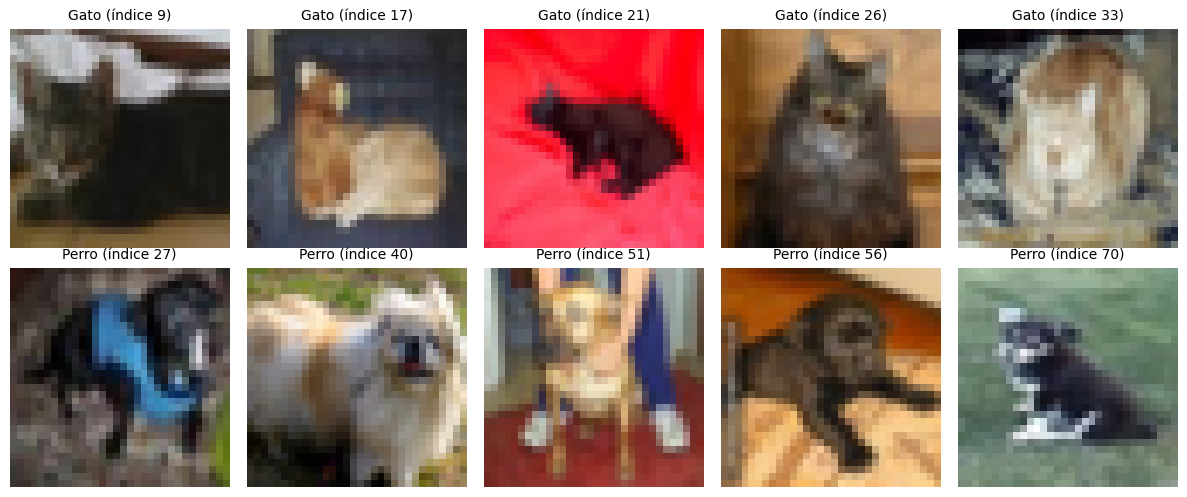

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Identificar los índices de las clases 'gato' (clase 3) y 'perro' (clase 5)
indices_gatos = np.where(y_train.ravel() == 3)[0][:5]
indices_perros = np.where(y_train.ravel() == 5)[0][:5]

# Crear la figura para mostrar los ejemplos
fig, ejes = plt.subplots(2, 5, figsize=(12, 5))

# Dibujar los 5 gatos en la primera fila
for i, idx in enumerate(indices_gatos):
    # Reescalar si ya están normalizados a [0, 1] o dejarlos como están
    img = X_train[idx]
    ejes[0, i].imshow(img)
    ejes[0, i].set_title(f"Gato (índice {idx})", fontsize=10)
    ejes[0, i].axis("off")

# Dibujar los 5 perros en la segunda fila
for i, idx in enumerate(indices_perros):
    img = X_train[idx]
    ejes[1, i].imshow(img)
    ejes[1, i].set_title(f"Perro (índice {idx})", fontsize=10)
    ejes[1, i].axis("off")

plt.tight_layout()
plt.show()

## 1.2. Components of Convolutional Neural Network (CNN)

In [ ]:
import tensorflow as tf
import numpy as np

print('TensorFlow version:', tf.__version__)
print('Numpy version:', np.__version__)

In [ ]:
def conv1d(x, w, p=0, s=1):
    w_rot = np.array(w[::-1])
    x_padded = np.array(x)
    if p > 0:
        zero_pad = np.zeros(shape=p)
        x_padded = np.concatenate([zero_pad, x_padded, zero_pad])
    res = []
    for i in range(0, int((len(x_padded) - len(w_rot)) / s) + 1, s):
        res.append(np.sum(x_padded[i:i+w_rot.shape[0]] * w_rot))
    return np.array(res)

# Test
x = [1, 3, 2, 4, 5, 6, 1, 3]
w = [1, 0, 3, 1, 2]

print('Conv1d rendered:', conv1d(x, w, p=2, s=1))
print('Numpy Result:', np.convolve(x, w, mode='same'))

Conv1d rendered: [ 5. 14. 16. 26. 24. 34. 19. 22.]
Numpy Result: [ 5 14 16 26 24 34 19 22]


In [ ]:
import scipy.signal

def conv2d(X, W, p=(0, 0), s=(1, 1)):
    W_rot = np.array(W)[::-1,::-1]
    X_orig = np.array(X)
    n1 = X_orig.shape[0] + 2 * p[0]
    n2 = X_orig.shape[1] + 2 * p[1]
    X_padded = np.zeros(shape=(n1, n2))
    X_padded[p[0]: p[0] + X_orig.shape[0],
             p[1]: p[1] + X_orig.shape[1]] = X_orig

    res = []
    for i in range(0, int((X_padded.shape[0] - W_rot.shape[0]) / s[0]) + 1, s[0]):
        res.append([])
        for j in range(0, int((X_padded.shape[1] - W_rot.shape[1]) / s[1]) + 1, s[1]):
            X_sub = X_padded[i: i+W_rot.shape[0], j: j+W_rot.shape[1]]
            res[-1].append(np.sum(X_sub * W_rot))
    return np.array(res)
# Test
X = [[1, 3, 2, 4], [5, 6, 1, 3], [1, 2, 0, 2], [3, 4, 3, 2]]
W = [[1, 0, 3], [1, 2, 1], [0, 1, 1]]

print('Rendering Conv2d:\n', conv2d(X, W, p=(1, 1), s=(1, 1)))
print('scipy results:\n', scipy.signal.convolve2d(X, W, mode='same'))

Rendering Conv2d:
 [[11. 25. 32. 13.]
 [19. 25. 24. 13.]
 [13. 28. 25. 17.]
 [11. 17. 14.  9.]]
scipy results:
 [[11 25 32 13]
 [19 25 24 13]
 [13 28 25 17]
 [11 17 14  9]]


## 1.3. Building Deep Convolution Neural Network Using Basic Components

In [ ]:
from tensorflow import keras

conv_layer = keras.layers.Conv2D(
    filters=16, kernel_size=(3, 3),
    kernel_regularizer=keras.regularizers.l2(0.001))

fc_layer = keras.layers.Dense(
    units=16, kernel_regularizer=keras.regularizers.l2(0.001))

In [ ]:
from distutils.version import LooseVersion as Version

######## Binary cross entropy
bce_probas = tf.keras.losses.BinaryCrossentropy(from_logits=False)
bce_logits = tf.keras.losses.BinaryCrossentropy(from_logits=True)

logits = tf.constant([0.8])
probas = tf.keras.activations.sigmoid(logits)
p = bce_probas(y_true=np.array([1]), y_pred=probas)
l = bce_logits(y_true=np.array([1]), y_pred=logits)
tf.print(f'BCE (probability): {p:.4f} (logit): {l:.4f}')

######## Categorical cross entropy
cce_probas = tf.keras.losses.CategoricalCrossentropy(from_logits=False)
cce_logits = tf.keras.losses.CategoricalCrossentropy(from_logits=True)

logits = tf.constant([[1.5, 0.8, 2.1]])
probas = tf.keras.activations.softmax(logits)

p = cce_probas(y_true=np.array([[0, 0, 1]]), y_pred=probas)
l = cce_logits(y_true=np.array([[0, 0, 1]]), y_pred=logits)
tf.print(f'CCE (probability): {p:.4f} (logit): {l:.4f}')

######## Sparse categorical cross entropy
sp_cce_probas = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
sp_cce_logits = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

p = sp_cce_probas(y_true=np.array([2]), y_pred=probas)
l = sp_cce_logits(y_true=np.array([2]), y_pred=logits)
tf.print(f'Sparse CCE (probability): {p:.4f} (logit): {l:.4f}')

BCE (probability): 0.3711 (logit): 0.3711
CCE (probability): 0.5996 (logit): 0.5996
Sparse CCE (probability): 0.5996 (logit): 0.5996


## 1.4. Building Convolutional Neural Network using TensorFlow

In [ ]:
import tensorflow_datasets as tfds
import pandas as pd

import matplotlib.pyplot as plt

In [ ]:
mnist_bldr = tfds.builder('mnist')
mnist_bldr.download_and_prepare()
datasets = mnist_bldr.as_dataset(shuffle_files=False)
print(datasets.keys())
mnist_train_orig, mnist_test_orig = datasets['train'], datasets['test']

dict_keys(['train', 'test'])


In [ ]:
BUFFER_SIZE = 10000
BATCH_SIZE = 64
NUM_EPOCHS = 20

In [ ]:
mnist_train = mnist_train_orig.map(
    lambda item: (tf.cast(item['image'], tf.float32)/255.0,
                  tf.cast(item['label'], tf.int32)))

mnist_test = mnist_test_orig.map(
    lambda item: (tf.cast(item['image'], tf.float32)/255.0,
                  tf.cast(item['label'], tf.int32)))

tf.random.set_seed(1)

mnist_train = mnist_train.shuffle(buffer_size=BUFFER_SIZE,
                                  reshuffle_each_iteration=False)

mnist_valid = mnist_train.take(10000).batch(BATCH_SIZE)
mnist_train = mnist_train.skip(10000).batch(BATCH_SIZE)

In [ ]:
model = tf.keras.Sequential()

model.add(tf.keras.layers.Conv2D(
    filters=32, kernel_size=(5, 5),
    strides=(1, 1), padding='same',
    data_format='channels_last',
    name='conv_1', activation='relu'))

model.add(tf.keras.layers.MaxPool2D(
    pool_size=(2, 2), name='pool_1'))

model.add(tf.keras.layers.Conv2D(
    filters=64, kernel_size=(5, 5),
    strides=(1, 1), padding='same',
    name='conv_2', activation='relu'))

model.add(tf.keras.layers.MaxPool2D(pool_size=(2, 2), name='pool_2'))

In [ ]:
model.compute_output_shape(input_shape=(16, 28, 28, 1))

(16, 7, 7, 64)

In [ ]:
model.add(tf.keras.layers.Flatten())

model.compute_output_shape(input_shape=(16, 28, 28, 1))

(16, 3136)

In [ ]:
model.add(tf.keras.layers.Dense(
    units=1024, name='fc_1',
    activation='relu'))

model.add(tf.keras.layers.Dropout(
    rate=0.5))

model.add(tf.keras.layers.Dense(
    units=10,
    name='fc_2',
    activation='softmax'))

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

history = model.fit(mnist_train, epochs=NUM_EPOCHS,
                    validation_data=mnist_valid,
                    shuffle=True)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.9582 - loss: 0.1360 - val_accuracy: 0.9839 - val_loss: 0.0507
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9860 - loss: 0.0444 - val_accuracy: 0.9885 - val_loss: 0.0389
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9908 - loss: 0.0288 - val_accuracy: 0.9887 - val_loss: 0.0422
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9929 - loss: 0.0225 - val_accuracy: 0.9893 - val_loss: 0.0415
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9940 - loss: 0.0187 - val_accuracy: 0.9882 - val_loss: 0.0438
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9948 - loss: 0.0160 - val_accuracy: 0.9901 - val_loss: 0.0389
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9962 - loss: 0.0131 - val_accuracy: 0.9902 - val_loss: 0.0421
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9956 - loss: 0.0132 - val_accuracy: 

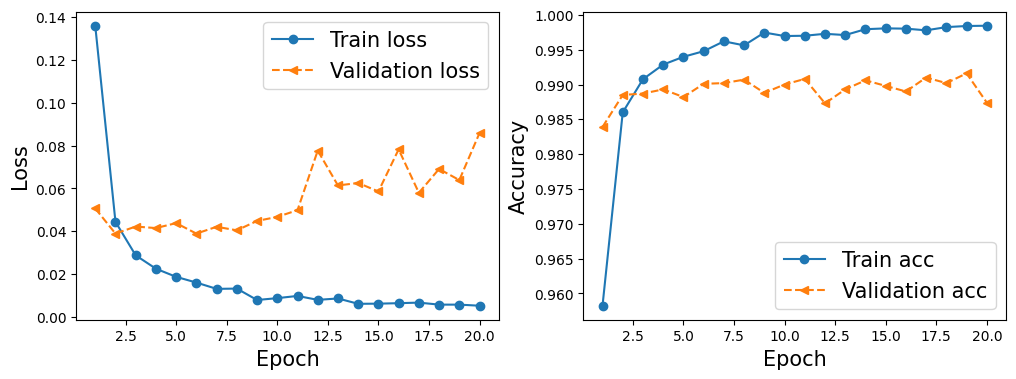

In [ ]:
hist = history.history
X_arr = np.arange(len(hist['loss'])) + 1

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(X_arr, hist['loss'], '-o', label='Train loss')
ax.plot(X_arr, hist['val_loss'], '--<', label='Validation loss')
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Loss', size=15)
ax.legend(fontsize=15)
ax = fig.add_subplot(1, 2, 2)
ax.plot(X_arr, hist['accuracy'], '-o', label='Train acc')
ax.plot(X_arr, hist['val_accuracy'], '--<', label='Validation acc')
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Accuracy', size=15)
ax.legend(fontsize=15)

plt.show()

In [ ]:
test_results = model.evaluate(mnist_test.batch(20))
print(f'test accuracy {test_results[1] * 100:.2f}%')

500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9904 - loss: 0.0571
test accuracy 99.04%


TensorShape([12, 10])
tf.Tensor([2 0 4 8 7 6 0 6 3 1 8 0], shape=(12,), dtype=int64)


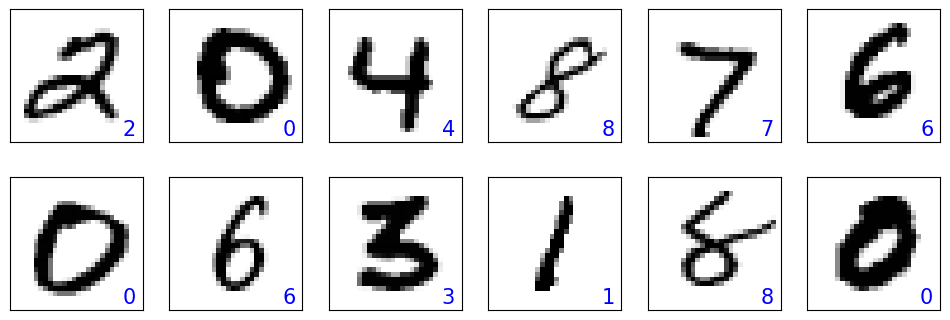

In [ ]:
batch_test = next(iter(mnist_test.batch(12)))
preds = model(batch_test[0])

tf.print(preds.shape)
preds = tf.argmax(preds, axis=1)
print(preds)

fig = plt.figure(figsize=(12, 4))
for i in range(12):
    ax = fig.add_subplot(2, 6, i+1)
    ax.set_xticks([]), ax.set_yticks([])
    img = batch_test[0][i, :, :, 0]
    ax.imshow(img, cmap='gray_r')
    ax.text(0.9, 0.1, f'{preds[i]}', size=15, color='blue',
            horizontalalignment='center', verticalalignment='center',
            transform=ax.transAxes)
plt.show()

In [ ]:
import os

if not os.path.exists('models'):
    os.mkdir('models')

model.save('models/mnist-cnn.keras')

In [ ]:
import tensorflow as tf
import numpy as np

# 1. Cargar el modelo original y evaluar
try:
    original_model = tf.keras.models.load_model('mnist-cnn.keras')
    print("✅ Modelo original cargado desde 'mnist-cnn.keras'")
    test_loss_orig, test_acc_orig = original_model.evaluate(mnist_test.batch(64), verbose=0)
    print(f"-> Precisión del modelo original en test: {test_acc_orig * 100:.2f}%")
except Exception as e:
    print(f"⚠️ No se pudo cargar el modelo original: {e}. Evaluando el modelo actual en memoria 'model'")
    test_loss_orig, test_acc_orig = model.evaluate(mnist_test.batch(64), verbose=0)
    print(f"-> Precisión del modelo en memoria en test: {test_acc_orig * 100:.2f}%")

# 2. Definir un nuevo modelo con Dropout adicional (Regularizado)
print("\n--- Creando y entrenando el nuevo modelo con Dropout adicional ---")
tf.random.set_seed(1)

model_dropout = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, kernel_size=(5, 5), strides=(1, 1), padding='same', activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25),  # Dropout después del primer bloque convolucional

    tf.keras.layers.Conv2D(64, kernel_size=(5, 5), strides=(1, 1), padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25),  # Dropout después del segundo bloque convolucional

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dropout(0.5),   # Dropout en la capa completamente conectada
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compilar el nuevo modelo
model_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

# Entrenar el nuevo modelo por 5 épocas para comparar rápido
history_dropout = model_dropout.fit(
    mnist_train,
    epochs=5,
    validation_data=mnist_valid,
    shuffle=True,
    verbose=1
)

# 3. Evaluar el nuevo modelo en el conjunto de test
test_loss_drop, test_acc_drop = model_dropout.evaluate(mnist_test.batch(64), verbose=0)
print("\n--- COMPARATIVA FINAL ---")
print(f"Exactitud Modelo Original: {test_acc_orig * 100:.2f}%")
print(f"Exactitud Modelo con más Dropout: {test_acc_drop * 100:.2f}%")

✅ Modelo original cargado desde 'mnist-cnn.keras'
-> Precisión del modelo original en test: 99.09%

--- Creando y entrenando el nuevo modelo con Dropout adicional ---
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.9486 - loss: 0.1629 - val_accuracy: 0.9839 - val_loss: 0.0541
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9818 - loss: 0.0585 - val_accuracy: 0.9864 - val_loss: 0.0470
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9861 - loss: 0.0444 - val_accuracy: 0.9879 - val_loss: 0.0407
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9886 - loss: 0.0371 - val_accuracy: 0.9914 - val_loss: 0.0313
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9903 - loss: 0.0302 - val_accuracy: 0.9899 - val_loss: 0.0349

--- COMPARATIVA FINAL ---
Exactitud Modelo Original: 99.09%
Exactitud Modelo con más Dropout: 99.30%


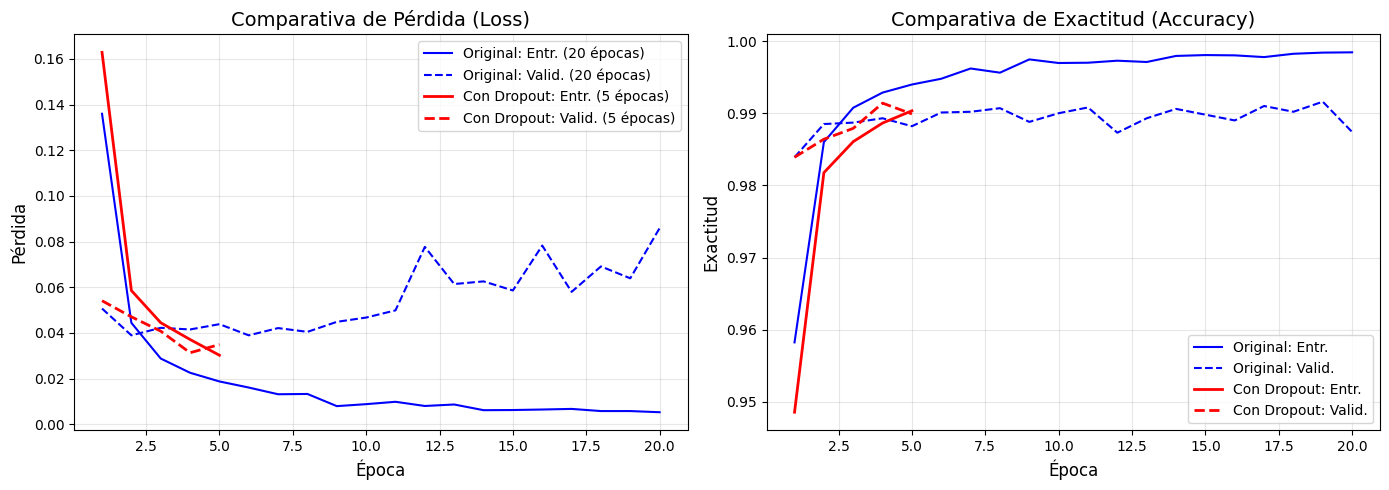

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Obtener historiales de ambos entrenamientos
# Nota: El original se entrenó por 20 épocas y el de dropout por 5 épocas.
hist_orig = history.history
hist_drop = history_dropout.history

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico de Pérdida (Loss) ---
ax1.plot(np.arange(1, len(hist_orig['loss']) + 1), hist_orig['loss'], 'b-', label='Original: Entr. (20 épocas)')
ax1.plot(np.arange(1, len(hist_orig['val_loss']) + 1), hist_orig['val_loss'], 'b--', label='Original: Valid. (20 épocas)')

ax1.plot(np.arange(1, len(hist_drop['loss']) + 1), hist_drop['loss'], 'r-', linewidth=2, label='Con Dropout: Entr. (5 épocas)')
ax1.plot(np.arange(1, len(hist_drop['val_loss']) + 1), hist_drop['val_loss'], 'r--', linewidth=2, label='Con Dropout: Valid. (5 épocas)')

ax1.set_title('Comparativa de Pérdida (Loss)', fontsize=14)
ax1.set_xlabel('Época', fontsize=12)
ax1.set_ylabel('Pérdida', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# --- Gráfico de Exactitud (Accuracy) ---
ax2.plot(np.arange(1, len(hist_orig['accuracy']) + 1), hist_orig['accuracy'], 'b-', label='Original: Entr.')
ax2.plot(np.arange(1, len(hist_orig['val_accuracy']) + 1), hist_orig['val_accuracy'], 'b--', label='Original: Valid.')

ax2.plot(np.arange(1, len(hist_drop['accuracy']) + 1), hist_drop['accuracy'], 'r-', linewidth=2, label='Con Dropout: Entr.')
ax2.plot(np.arange(1, len(hist_drop['val_accuracy']) + 1), hist_drop['val_accuracy'], 'r--', linewidth=2, label='Con Dropout: Valid.')

ax2.set_title('Comparativa de Exactitud (Accuracy)', fontsize=14)
ax2.set_xlabel('Época', fontsize=12)
ax2.set_ylabel('Exactitud', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Elegir el optimizador

Todos los optimizadores hacen lo mismo en esencia: usan el gradiente de la loss para decidir cómo mover los pesos. Se diferencian en **cuánto** y **en qué dirección** se mueve cada peso en cada paso.

**SGD (descenso de gradiente estocástico)** es el más simple: $w \leftarrow w - \eta \nabla L$, con la misma tasa de aprendizaje $\eta$ para todos los pesos. Es sensible a la elección de $\eta$ y avanza lento en zonas planas o en "valles" alargados de la función de pérdida.

**SGD con momentum** acumula una especie de velocidad: si el gradiente apunta varias veces seguidas hacia el mismo lado, acelera; si oscila, las oscilaciones se cancelan. Corrige buena parte de los problemas de SGD puro.

**RMSprop y Adagrad** introducen tasas **adaptativas por parámetro**: cada peso se escala según la magnitud histórica de sus gradientes. Los pesos con gradientes grandes dan pasos más chicos y viceversa.

**Adam** combina ambas ideas: momentum (promedio de gradientes) y escalamiento adaptativo (promedio de gradientes al cuadrado), con una corrección de sesgo al inicio. Por eso funciona razonablemente bien "de fábrica" con `lr=1e-3` en casi cualquier problema.

**AdamW** corrige cómo Adam maneja la regularización L2 (*weight decay*), aplicándola de forma desacoplada. Hoy es el estándar para entrenar transformers y modelos grandes.

### Criterios prácticos

| Situación | Elección razonable |
|---|---|
| Prototipo, primer intento, poco tiempo para ajustar | Adam (`lr=1e-3`) |
| Transformers, LLMs, fine-tuning de modelos preentrenados | AdamW con *warmup* y *scheduler* |
| CNNs para visión donde importa la mejor generalización final | SGD + momentum (0,9) con *learning rate schedule* |
| Redes recurrentes (RNN/LSTM) | Adam o RMSprop |
| Datos dispersos (embeddings, texto con bolsa de palabras) | Adam o Adagrad |
| Memoria GPU muy limitada | SGD + momentum (Adam guarda dos estados extra por parámetro, triplicando la memoria del optimizador) |

El principio de fondo es un **trade-off entre comodidad y techo de rendimiento**. Adam converge rápido y tolera mal ajuste de hiperparámetros, pero hay evidencia (Wilson et al., 2017) de que en algunas tareas de visión SGD bien ajustado generaliza algo mejor. SGD, a cambio, exige más trabajo en la tasa de aprendizaje y su calendario.

Dos observaciones importantes. Primero, **la tasa de aprendizaje suele importar más que el optimizador**: un Adam con `lr` mal elegido rinde peor que un SGD bien ajustado, y viceversa. Segundo, si un artículo o modelo de referencia en tu dominio usa cierto optimizador con ciertos hiperparámetros, partir desde ahí ahorra mucho tiempo.

Para el modelo de MNIST de tu notebook, Adam con valores por defecto es la elección sensata.

## Elegir la loss

La loss no se elige por gusto: se deduce principalmente de **qué tipo de salida predice el modelo**. Hay un fundamento teórico detrás: la mayoría de las losses estándar equivalen a maximizar la verosimilitud bajo cierta suposición de distribución de los datos. MSE corresponde a suponer ruido gaussiano; la entropía cruzada, a una distribución categórica o Bernoulli.

### Según el tipo de problema

| Problema | Activación de salida | Loss |
|---|---|---|
| Clasificación multiclase, etiquetas enteras (0–9) | `softmax` | `sparse_categorical_crossentropy` |
| Clasificación multiclase, etiquetas *one-hot* | `softmax` | `categorical_crossentropy` |
| Clasificación binaria | `sigmoid` (1 neurona) | `binary_crossentropy` |
| Multietiqueta (varias clases a la vez) | `sigmoid` (1 neurona por clase) | `binary_crossentropy` |
| Regresión estándar | lineal (sin activación) | `mse` |
| Regresión con outliers | lineal | `mae` o `huber` |
| Conteos (visitas, eventos) | exponencial / softplus | `poisson` |

La regla clave es que **activación de salida y loss van en pareja**. Softmax con MSE, por ejemplo, entrena pero con gradientes pobres; softmax con entropía cruzada produce gradientes limpios.

### Principios adicionales

**Robustez a outliers.** MSE eleva los errores al cuadrado, así que un dato anómalo domina el entrenamiento. MAE penaliza linealmente y es más robusta; Huber se comporta como MSE para errores chicos y como MAE para errores grandes, combinando lo mejor de ambas.

**Clases desbalanceadas.** Si el 95 % de los ejemplos es de una clase, la entropía cruzada estándar premia predecir siempre esa clase. Las opciones son ponderar la loss por clase (`class_weight` en `fit`) o usar *focal loss*, que reduce el peso de los ejemplos fáciles.

**Estabilidad numérica.** En Keras conviene dejar la última capa sin activación y usar `from_logits=True` en la loss:

```python
tf.keras.layers.Dense(10)  # sin softmax
...
loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
```

Así TensorFlow combina softmax y logaritmo en una sola operación numéricamente estable, evitando problemas con probabilidades muy cercanas a 0.

**La loss no es la métrica.** La loss tiene que ser diferenciable para poder optimizarla; la métrica que te importa (accuracy, F1, recall) muchas veces no lo es. Por eso se optimiza entropía cruzada y se reporta accuracy. Si la métrica relevante es muy distinta de la loss, a veces vale la pena diseñar una loss más cercana a ella.

**Losses para tareas especiales.** Más allá de las básicas existen losses diseñadas para objetivos específicos: *contrastive* y *triplet loss* para aprender embeddings de similitud, *Dice loss* para segmentación de imágenes, y losses de ranking (BPR, por ejemplo) en sistemas de recomendación.

La regularización agrupa las técnicas que buscan que el modelo **generalice**, es decir, que rinda bien en datos nuevos y no solo memorice el conjunto de entrenamiento. El síntoma que combaten es el *overfitting*: accuracy de entrenamiento alta y de validación estancada o bajando.

Las CNN tienen técnicas propias porque sus datos (imágenes) tienen estructura espacial: píxeles vecinos están correlacionados, y eso cambia cómo funcionan algunas regularizaciones clásicas.

## 1. Regularización de pesos (L2 y L1)

Agrega a la loss un término que penaliza pesos grandes:

$$L_{\text{total}} = L_{\text{datos}} + \lambda \sum_i w_i^2 \quad \text{(L2)} \qquad L_{\text{total}} = L_{\text{datos}} + \lambda \sum_i |w_i| \quad \text{(L1)}$$

**L2** empuja los pesos hacia valores pequeños y repartidos, lo que produce funciones más suaves y menos sensibles a variaciones mínimas en la entrada. Es la más usada en CNN. **L1** empuja muchos pesos exactamente a cero (modelos dispersos), pero en visión se usa poco.

```python
from tensorflow.keras import regularizers

tf.keras.layers.Conv2D(64, 3, activation='relu',
                       kernel_regularizer=regularizers.l2(1e-4))
```

Valores típicos de $\lambda$: entre `1e-5` y `1e-3`. Con Adam conviene usar **AdamW** (*weight decay* desacoplado) en vez de L2 en la loss, porque en Adam ambas cosas no son equivalentes.

## 2. Dropout y sus variantes espaciales

**Dropout** apaga aleatoriamente una fracción de neuronas en cada paso de entrenamiento (en inferencia se desactiva). Obliga a la red a no depender de neuronas específicas y equivale aproximadamente a entrenar un conjunto de muchas subredes.

En CNN tiene un problema: si se apagan píxeles sueltos de un mapa de características, sus vecinos contienen casi la misma información, así que el efecto regularizador es débil. Por eso hay variantes:

**SpatialDropout2D** apaga **canales completos** (mapas de características enteros) en vez de píxeles individuales.

**DropBlock** apaga **regiones contiguas** del mapa, obligando a la red a mirar otras partes de la imagen.

Uso típico en Keras:

```python
tf.keras.layers.Conv2D(64, 3, activation='relu'),
tf.keras.layers.SpatialDropout2D(0.1),   # entre capas convolucionales
...
tf.keras.layers.Flatten(),
tf.keras.layers.Dense(128, activation='relu'),
tf.keras.layers.Dropout(0.5),            # en la parte densa
```

El dropout clásico se pone sobre todo en las capas densas finales, que es donde se concentran los parámetros y el riesgo de memorización. Tasas habituales: 0,1–0,2 en convolucionales, 0,3–0,5 en densas.

## 3. Batch Normalization

Normaliza las activaciones de cada capa usando la media y varianza del batch, y luego aplica una escala y desplazamiento aprendibles. Su propósito principal es estabilizar y acelerar el entrenamiento, pero tiene un **efecto regularizador lateral**: como las estadísticas cambian de batch en batch, introduce un ruido leve en cada ejemplo.

```python
tf.keras.layers.Conv2D(64, 3, use_bias=False),
tf.keras.layers.BatchNormalization(),
tf.keras.layers.Activation('relu'),
```

Al usar BatchNorm, el sesgo de la capa anterior sobra (la normalización lo anula), por eso `use_bias=False`. Combinar BatchNorm con dropout en la misma zona de la red puede generar conflictos, así que muchas arquitecturas modernas usan BatchNorm en la parte convolucional y dropout solo al final.

## 4. Data augmentation

Probablemente la regularización **más efectiva en visión**. Consiste en generar variaciones de las imágenes de entrenamiento que no cambian su clase: rotaciones, volteos, recortes, zoom, cambios de brillo o contraste. El modelo aprende invariancias que de otro modo tendría que inferir de muchos más datos.

```python
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

model = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    data_augmentation,       # solo actúa durante el entrenamiento
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    ...
])
```

El principio clave es que **las transformaciones deben respetar la semántica del problema**. En MNIST no conviene voltear horizontalmente ni rotar mucho (un 6 rotado se convierte en un 9); en fotos de gatos el volteo horizontal es perfectamente válido.

Variantes más avanzadas mezclan imágenes: **Mixup** combina linealmente dos imágenes y sus etiquetas; **CutMix** pega un recorte de una imagen sobre otra, con etiquetas proporcionales al área; **Cutout / Random Erasing** borra un rectángulo aleatorio de la imagen.

## 5. Global Average Pooling en vez de Flatten

Retomando la primera pregunta: `Flatten` seguido de una capa densa genera una enorme cantidad de parámetros (en tu DNN, el 97 % del total estaba ahí). **GlobalAveragePooling2D** reemplaza cada mapa de características por su promedio, reduciendo drásticamente los parámetros y por lo tanto la capacidad de memorizar.

```python
tf.keras.layers.Conv2D(128, 3, activation='relu'),
tf.keras.layers.GlobalAveragePooling2D(),   # (h, w, 128) -> (128)
tf.keras.layers.Dense(10, activation='softmax'),
```

Es una regularización **arquitectónica**: en vez de penalizar, limita estructuralmente lo que el modelo puede aprender. Es el estándar desde ResNet en adelante.

## 6. Label smoothing

En vez de entrenar con etiquetas duras como `[0, 0, 1, 0, ...]`, se suavizan, por ejemplo a `[0.01, 0.01, 0.91, 0.01, ...]`. Evita que el modelo se vuelva sobreconfiado y empuje los logits hacia valores extremos.

```python
loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
```

Requiere etiquetas *one-hot* (la versión `sparse` de Keras no acepta este parámetro).

## 7. Early stopping

Detiene el entrenamiento cuando la loss de validación deja de mejorar, y opcionalmente recupera los mejores pesos. Limita cuánto puede el modelo ajustarse al ruido del entrenamiento.

```python
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)

model.fit(x_train, y_train, validation_split=0.1,
          epochs=100, callbacks=[early_stop])
```

## 8. Stochastic depth

Específica de redes muy profundas con conexiones residuales (ResNet y derivadas): durante el entrenamiento se saltan bloques residuales completos de forma aleatoria. Es como dropout pero a nivel de capas enteras. Se usa en arquitecturas grandes como EfficientNet o ConvNeXt.

## Cómo combinarlas

No conviene aplicarlas todas a la vez sin criterio: el exceso de regularización produce *underfitting* (el modelo no aprende ni siquiera el entrenamiento). Un orden razonable para una CNN nueva es:

1. **Data augmentation** apropiada al dominio, que casi siempre ayuda.
2. **BatchNorm** en los bloques convolucionales y **Global Average Pooling** al final.
3. **Weight decay** pequeño (`1e-4`), o AdamW.
4. **Dropout** en las capas densas finales si sigue habiendo overfitting.
5. **Early stopping** como red de seguridad.
6. Label smoothing, Mixup o CutMix si se busca exprimir el último punto de accuracy.

El diagnóstico siempre parte de comparar las curvas de entrenamiento y validación: si están juntas y ambas son malas, el problema es falta de capacidad y hay que **reducir** regularización o agrandar el modelo; si se separan, hay que agregarla.

Esta celda hace la **evaluación final** del modelo CNN: mide qué tan bien funciona con imágenes que nunca vio durante el entrenamiento.

## El código, línea por línea

```python
test_results = model.evaluate(mnist_test.batch(20))
print(f'test accuracy {test_results[1] * 100:.2f}%')
```

**`mnist_test`** es el conjunto de prueba de MNIST, cargado como un `tf.data.Dataset` (probablemente con `tensorflow_datasets`). Contiene **10.000 imágenes** de dígitos con sus etiquetas, separadas desde el inicio de las 60.000 de entrenamiento.

**`.batch(20)`** agrupa el dataset en lotes de 20 imágenes. El modelo procesa un lote a la vez en lugar de imagen por imagen, lo que aprovecha mejor la GPU o CPU. Con 10.000 imágenes y lotes de 20 resultan exactamente **500 lotes**, que es el `500/500` que aparece en la salida.

**`model.evaluate(...)`** recorre todos los lotes y, para cada uno, hace una pasada hacia adelante (predice), compara las predicciones con las etiquetas reales y acumula la loss y las métricas. A diferencia de `fit`, **no calcula gradientes ni modifica los pesos**: el modelo queda exactamente igual. Además, las capas como `Dropout` se desactivan y `BatchNormalization` usa las estadísticas aprendidas en el entrenamiento, no las del lote.

**`test_results`** es una lista con los valores finales, en el mismo orden en que se definieron en `compile`: primero la loss y luego cada métrica. Si el modelo se compiló con `metrics=['accuracy']`, entonces:

- `test_results[0]` → loss = 0.0526
- `test_results[1]` → accuracy = 0.9920

**`print(f'...')`** usa un *f-string*: `test_results[1] * 100` convierte la proporción a porcentaje, y `:.2f` lo formatea con dos decimales. De ahí sale `99.20%`.

## Lectura de la salida

```
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9920 - loss: 0.0526
test accuracy 99.20%
```

**`500/500`** indica que se procesaron los 500 lotes; la barra de progreso está completa.

**`4s 7ms/step`** es el tiempo total (4 segundos) y el tiempo promedio por lote (7 milisegundos). Un *step* aquí es un lote, no una imagen.

**`accuracy: 0.9920`** significa que el modelo acertó el 99,20 % de las imágenes de prueba: **9.920 aciertos y 80 errores** de 10.000.

**`loss: 0.0526`** es la entropía cruzada promedio. Se puede interpretar así: $e^{-0.0526} \approx 0.95$, es decir, en promedio (geométrico) el modelo asigna cerca de un **95 % de probabilidad a la clase correcta**. La accuracy solo mira si la clase más probable es la correcta; la loss además mide *cuán seguro* estaba el modelo. Por eso la loss es más sensible: dos modelos con igual accuracy pueden tener losses distintas si uno acierta con más confianza.

## Por qué importa este resultado

El conjunto de prueba funciona como un "examen final" con preguntas nuevas. Si el modelo solo hubiera memorizado el entrenamiento, aquí su rendimiento caería. Un 99,20 % en prueba indica que **generaliza bien**.

Comparado con la DNN densa que vimos antes (alrededor de 97 % en MNIST), la CNN reduce los errores aproximadamente a un tercio: de unos 300 a 80. Esa mejora viene justamente de que las capas convolucionales conservan la estructura espacial de la imagen, que el `Flatten` directo destruía.

## Detalles y buenas prácticas

**El tamaño del lote no cambia el resultado.** Con `batch(20)` o `batch(256)` la accuracy sería la misma, porque en evaluación no se actualizan pesos. Solo cambia la velocidad y el uso de memoria.

**El preprocesamiento debe ser idéntico al del entrenamiento.** Si las imágenes de entrenamiento se normalizaron dividiendo por 255, las de prueba deben pasar por lo mismo (típicamente con un `.map(...)` antes del `.batch`). Si no, la accuracy cae drásticamente aunque el modelo sea bueno.

**El test se usa una sola vez, al final.** Si se ajustan hiperparámetros mirando este resultado, el conjunto de prueba deja de ser independiente y el 99,20 % pasa a ser optimista. Para ajustar se usa el conjunto de **validación**.

**Acceso más legible a los resultados.** En vez de recordar índices, se puede pedir un diccionario:

```python
test_results = model.evaluate(mnist_test.batch(20), return_dict=True)
print(f"test accuracy {test_results['accuracy'] * 100:.2f}%")
```

**La accuracy global no muestra todo.** Los 80 errores podrían concentrarse en pares específicos (4 con 9, 3 con 5, 7 con 1). Para verlo conviene una **matriz de confusión** con `model.predict` y `tf.math.confusion_matrix`, y mirar algunas de las imágenes mal clasificadas, que a menudo son dígitos que incluso a una persona le costaría leer.

Forma de la foto: (427, 640)


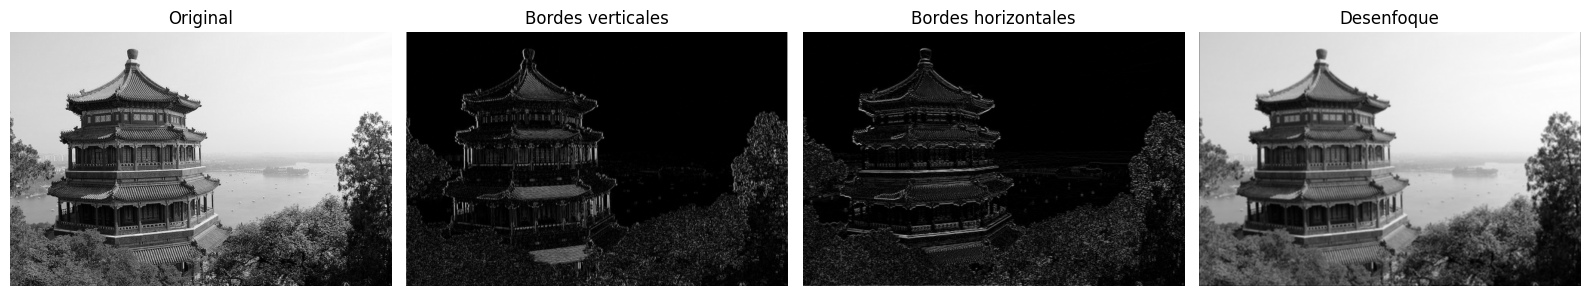

In [ ]:
from sklearn.datasets import load_sample_image

foto = load_sample_image("china.jpg").mean(axis=2).astype("float32") / 255.0     # a escala de grises, de 0 a 1
print("Forma de la foto:", foto.shape)

filtros = {
    "Bordes verticales": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype="float32"),
    "Bordes horizontales": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype="float32"),
    "Desenfoque": np.full((3, 3), 1 / 9, dtype="float32"),
}

entrada = foto[np.newaxis, :, :, np.newaxis]          # TensorFlow espera (lote, alto, ancho, canales)
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))
ejes[0].imshow(foto, cmap="gray"); ejes[0].set_title("Original")
for ax, (nombre, f) in zip(ejes[1:], filtros.items()):
    mapa = tf.nn.conv2d(entrada, f[:, :, np.newaxis, np.newaxis], strides=1, padding="SAME")[0, :, :, 0]
    ax.imshow(np.abs(mapa) if "Bordes" in nombre else mapa, cmap="gray"); ax.set_title(nombre)
for ax in ejes: ax.axis("off")
plt.tight_layout(); plt.show()

**Qué deberías ver:** el filtro vertical resalta los bordes verticales (columnas, árboles), el horizontal los horizontales (techos, el horizonte) y el desenfoque suaviza la foto.

**La idea clave:** estos filtros los diseñó una persona. **Una CNN aprende sus propios filtros**, los que más le sirven para la tarea, y en las capas profundas combina los rasgos simples en patrones complejos. Lo veremos en el Paso 1.4.

## Paso 1.3. Stride y padding (láminas 28 a 36)

| Concepto | Qué es | En Keras |
|---|---|---|
| **Padding** (relleno) | Agregar ceros en el borde para que el filtro quepa en las orillas | `padding="valid"` (sin relleno) o `"same"` (la salida mide lo mismo que la entrada) |
| **Stride** (paso) | Cuántos pixeles avanza el filtro en cada movimiento | `strides=1` (de a uno) o `2` (de a dos: la salida queda a la mitad) |

$$\text{lado de salida} = \left\lfloor \frac{n - k + 2p}{s} \right\rfloor + 1$$

con $n$ el lado de la entrada, $k$ el del filtro, $p$ el relleno y $s$ el paso.

In [ ]:
imagen = tf.zeros((1, 32, 32, 3))
for padding in ["valid", "same"]:
    for stride in [1, 2]:
        salida = layers.Conv2D(8, (3, 3), strides=stride, padding=padding)(imagen)
        print(f"padding={padding:5s} stride={stride} → forma de salida {salida.shape[1:]}")

padding=valid stride=1 → forma de salida (30, 30, 8)
padding=valid stride=2 → forma de salida (15, 15, 8)
padding=same  stride=1 → forma de salida (32, 32, 8)
padding=same  stride=2 → forma de salida (16, 16, 8)


**Qué deberías ver:** con `valid` y paso 1, 32 pasa a 30; con `same` y paso 1, queda en 32; con paso 2, se reduce a la mitad (15 o 16).

### Ejercicio 2
Con la fórmula: una imagen de **64 × 64**, un filtro de **5 × 5**, sin relleno y con paso **1**. ¿Qué lado tiene la salida? Guárdalo en `lado_a`. ¿Y con el mismo filtro, sin relleno y paso **2**? Guárdalo en `lado_b`.

In [ ]:
lado_a = None   # TU CÓDIGO AQUÍ
lado_b = None   # TU CÓDIGO AQUÍ
print(lado_a, lado_b)

None None


In [ ]:
revisar(lambda: lado_a == 60 and lado_b == 30)

Todavía no. Revisa tu respuesta.


## Paso 1.4. Los filtros que aprende una red

**Qué vamos a hacer:** entrenar rápido una CNN con Fashion-MNIST (la de la Clase 15) y mirar dentro: sus filtros y lo que produce cada uno con una imagen.

In [ ]:
(Xf_tr, yf_tr), (Xf_te, yf_te) = keras.datasets.fashion_mnist.load_data()
Xf_tr = (Xf_tr / 255.0).reshape(-1, 28, 28, 1).astype("float32")
Xf_te = (Xf_te / 255.0).reshape(-1, 28, 28, 1).astype("float32")
PRENDAS = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo", "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

keras.utils.set_random_seed(42)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu", name="conv1"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu", name="conv2"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.fit(Xf_tr, yf_tr, epochs=2, batch_size=128, verbose=0)
print("Exactitud en prueba:", round(cnn.evaluate(Xf_te, yf_te, verbose=0)[1], 3))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Exactitud en prueba: 0.837


Forma de los pesos de conv1: (3, 3, 1, 16) → (alto, ancho, canales de entrada, filtros)


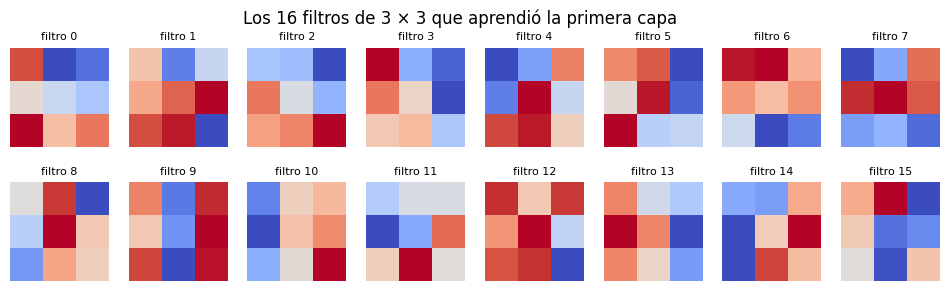

In [ ]:
pesos, sesgos = cnn.get_layer("conv1").get_weights()
print("Forma de los pesos de conv1:", pesos.shape, "→ (alto, ancho, canales de entrada, filtros)")

fig, ejes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(ejes.ravel()):
    ax.imshow(pesos[:, :, 0, i], cmap="coolwarm"); ax.set_title(f"filtro {i}", fontsize=8); ax.axis("off")
plt.suptitle("Los 16 filtros de 3 × 3 que aprendió la primera capa"); plt.show()

**Qué deberías ver:** 16 pequeños cuadros de 3 × 3. Varios se parecen a los filtros de bordes del Paso 1.2 (rojo de un lado, azul del otro): **la red descubrió sola que los bordes sirven**.

Ahora, lo que produce cada filtro con una imagen. Para eso armamos un modelo que entrega la salida de la capa `conv1` en vez de la clase:

Prenda: Botín | Forma de los mapas: (1, 26, 26, 16)


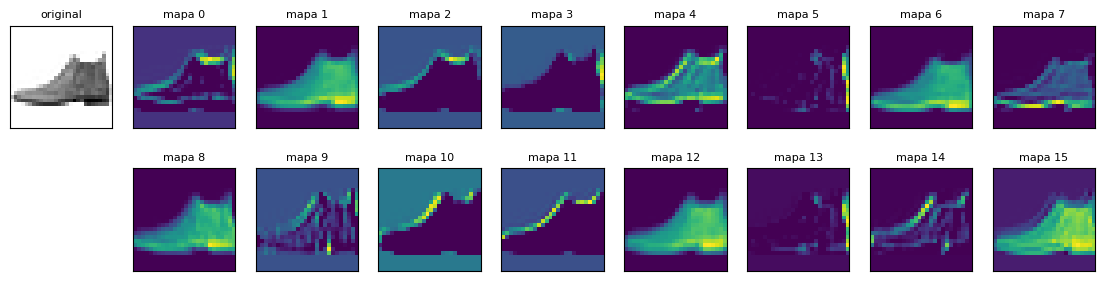

In [ ]:
espia = keras.Model(inputs=cnn.inputs, outputs=cnn.get_layer("conv1").output)
imagen = Xf_te[0:1]
mapas = espia.predict(imagen, verbose=0)
print("Prenda:", PRENDAS[yf_te[0]], "| Forma de los mapas:", mapas.shape)

fig, ejes = plt.subplots(2, 9, figsize=(14, 3.4))
ejes[0, 0].imshow(imagen[0, :, :, 0], cmap="gray_r"); ejes[0, 0].set_title("original", fontsize=8)
ejes[1, 0].axis("off")
for i, ax in enumerate(np.delete(ejes.ravel(), [0, 9])[:16]):
    ax.imshow(mapas[0, :, :, i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=8)
for ax in ejes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Qué deberías ver:** 16 versiones de la prenda, cada una resaltando algo distinto: el contorno izquierdo, el derecho, la parte superior, las zonas oscuras. Esos 16 mapas son la entrada de la segunda capa, que los combina.

### Ejercicio 3
Arma un modelo `espia2` que entregue la salida de la capa **`conv2`**, aplícalo a `imagen` y guarda en `forma_conv2` la forma del resultado (como tupla). Antes de ejecutarlo, piensa: ¿cuántos mapas tendrá y de qué tamaño?

In [ ]:
forma_conv2 = None  # TU CÓDIGO AQUÍ
print(forma_conv2)

None


In [ ]:
revisar(lambda: tuple(forma_conv2) == (1, 11, 11, 32))

Todavía no. Revisa tu respuesta.


---
# Parte 2. Mejorar una CNN: CIFAR-10 (láminas 37 a 69)

En la Clase 15, una CNN simple llegó a cerca de 70% con CIFAR-10 (10 clases de objetos a color). Hoy la mejoramos **cambio por cambio**, midiendo cada uno, como se hace en un proyecto real.

In [ ]:
(Xc_tr, yc_tr), (Xc_te, yc_te) = keras.datasets.cifar10.load_data()
yc_tr, yc_te = yc_tr.ravel(), yc_te.ravel()
Xc_tr, Xc_te = Xc_tr.astype("float32") / 255.0, Xc_te.astype("float32") / 255.0
CLASES = ["avión", "auto", "pájaro", "gato", "ciervo", "perro", "rana", "caballo", "barco", "camión"]
print("Entrenamiento:", Xc_tr.shape, "| Prueba:", Xc_te.shape)

EPOCAS = 10          # con GPU, cada modelo tarda 1 a 3 minutos
resultados = {}

def entrenar_y_medir(nombre, modelo, epocas=EPOCAS):
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = time.time()
    h = modelo.fit(Xc_tr, yc_tr, epochs=epocas, batch_size=128, validation_split=0.1, verbose=0)
    exac = modelo.evaluate(Xc_te, yc_te, verbose=0)[1]
    resultados[nombre] = {"exactitud prueba": exac,
                          "exactitud entrenamiento": h.history["accuracy"][-1],
                          "brecha (sobreajuste)": h.history["accuracy"][-1] - h.history["val_accuracy"][-1],
                          "parámetros": modelo.count_params(), "segundos": time.time() - inicio}
    print(f"{nombre}: exactitud en prueba {exac:.3f}")
    return h

**La columna "brecha"** es la diferencia entre la exactitud de entrenamiento y la de validación. Si es grande, el modelo está **memorizando** (sobreajuste).

## Paso 2.1. El punto de partida: la CNN de la Clase 15

In [ ]:
keras.utils.set_random_seed(42)
base = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
h_base = entrenar_y_medir("1. Base (Clase 15)", base)

## Paso 2.2. Bloques dobles y normalización por lotes

Dos cambios que usan casi todas las CNN modernas:

- **Bloques dobles:** dos convoluciones seguidas antes de cada pooling. La red "mira" dos veces a la misma escala antes de reducir.
- **`BatchNormalization`:** normaliza las salidas de una capa en cada lote (las deja con media cercana a 0 y desviación cercana a 1). Es como el `StandardScaler`, pero **dentro** de la red y en cada capa. Estabiliza y acelera el entrenamiento.

Escribimos una función para no repetir código:

In [ ]:
def bloque(filtros):
    """Dos convoluciones con normalización, y un pooling."""
    return [layers.Conv2D(filtros, (3, 3), padding="same", activation="relu"), layers.BatchNormalization(),
            layers.Conv2D(filtros, (3, 3), padding="same", activation="relu"), layers.BatchNormalization(),
            layers.MaxPooling2D(), layers.Dropout(0.25)]

keras.utils.set_random_seed(42)
profunda = keras.Sequential([layers.Input(shape=(32, 32, 3))] + bloque(32) + bloque(64) + bloque(128) +
                            [layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dropout(0.5),
                             layers.Dense(10, activation="softmax")])
h_prof = entrenar_y_medir("2. Bloques dobles + BatchNorm", profunda)

## Paso 2.3. Aumento de datos

> **Aumento de datos (data augmentation):** crear variaciones de las imágenes de entrenamiento en cada época (voltearlas, rotarlas un poco, desplazarlas). Un gato volteado sigue siendo un gato: la red aprende a reconocerlo aunque cambie de posición, y le cuesta más memorizar.

Keras lo hace con capas que **solo actúan al entrenar** (al predecir, dejan pasar la imagen intacta). Veamos qué hacen:

In [ ]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),            # voltear izquierda-derecha
    layers.RandomRotation(0.05),                # rotar hasta 18 grados
    layers.RandomTranslation(0.1, 0.1),         # desplazar hasta 10%
], name="aumento")

ejemplo = Xc_tr[7:8]
fig, ejes = plt.subplots(1, 8, figsize=(13, 2))
ejes[0].imshow(ejemplo[0]); ejes[0].set_title("original", fontsize=9)
for ax in ejes[1:]:
    ax.imshow(np.clip(aumento(ejemplo, training=True)[0], 0, 1)); ax.set_title("aumentada", fontsize=9)
for ax in ejes: ax.axis("off")
plt.show()

**Qué deberías ver:** la misma imagen 7 veces, cada vez un poco distinta.

### Ejercicio 4
Construye `con_aumento`: la misma red `profunda` del Paso 2.2, pero con la capa `aumento` **justo después del `Input`**. Entrénala con `entrenar_y_medir("3. + Aumento de datos", con_aumento)` y guarda lo que devuelve en `h_aum`.

Pista: `keras.Sequential([layers.Input(...), aumento] + bloque(32) + ...)`.

In [ ]:
keras.utils.set_random_seed(42)
con_aumento = None   # TU CÓDIGO AQUÍ
h_aum = None         # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: con_aumento.layers[0].name == "aumento" and "3. + Aumento de datos" in resultados)

## Paso 2.4. Comparar

In [ ]:
tabla = pd.DataFrame(resultados).T
tabla["parámetros"] = tabla["parámetros"].astype(int)
display(tabla.round(3))

plt.figure(figsize=(7, 4))
for nombre, h in [("Base", h_base), ("BatchNorm", h_prof), ("Aumento", h_aum)]:
    if h is not None:
        plt.plot(h.history["val_accuracy"], label=nombre)
plt.xlabel("Época"); plt.ylabel("Exactitud en validación"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Qué deberías ver** (los números exactos varían):

- La **base** cerca de 0,70, con una brecha que crece: empieza a memorizar.
- Con **bloques dobles y BatchNorm**, un salto claro, cerca de 0,80.
- Con **aumento de datos**, una **brecha mucho menor**. Con solo 10 épocas, su exactitud puede quedar parecida o incluso un poco bajo la anterior, porque aprende más lento; con 30 o más épocas, suele pasar adelante, porque sobreajusta menos.

**La lección:** cada mejora se mide por separado y se mira más de una columna. Una exactitud parecida con mucha menos brecha es un modelo que generalizará mejor.

### Ejercicio 5
Guarda en `mejor_cifar` el nombre del modelo con **mayor exactitud en prueba**, y en `menor_brecha` el nombre del que tiene **menor brecha**. Usa `tabla`.

In [ ]:
mejor_cifar = None   # TU CÓDIGO AQUÍ
menor_brecha = None  # TU CÓDIGO AQUÍ
print(mejor_cifar, "|", menor_brecha)

In [ ]:
revisar(lambda: mejor_cifar == tabla["exactitud prueba"].astype(float).idxmax() and menor_brecha == tabla["brecha (sobreajuste)"].astype(float).idxmin())

### Ejercicio 6
¿Qué le cuesta más al mejor modelo? Con su matriz de confusión, encuentra el par de clases más confundido (sin contar la diagonal) y guárdalo en `par_cifar` como tupla de nombres `(real, predicha)`. Usa el modelo `profunda`.

In [ ]:
from sklearn.metrics import confusion_matrix

par_cifar = None  # TU CÓDIGO AQUÍ
print(par_cifar)

In [ ]:
_cm = confusion_matrix(yc_te, profunda.predict(Xc_te, verbose=0).argmax(axis=1)); np.fill_diagonal(_cm, 0)
_i, _j = np.unravel_index(_cm.argmax(), _cm.shape)
revisar(lambda: tuple(par_cifar) == (CLASES[_i], CLASES[_j]))

**Qué deberías ver:** casi siempre **gato con perro**. Animales del mismo tamaño, en posiciones parecidas, en 32 × 32 pixeles.

---
# Parte 3. RNN con muchos datos: reseñas de películas (láminas 70 a 80)

En la Clase 13, una LSTM entrenada con **60 reseñas** perdió contra una regresión logística con TF-IDF. Dijimos que las redes necesitan muchos datos. Hoy lo comprobamos con **IMDb**: 50.000 reseñas de películas en inglés, positivas o negativas, que vienen con Keras.

## Paso 3.1. Los datos

IMDb ya viene **codificado como números enteros** (Clase 12): cada palabra es su posición en el ranking de frecuencia. Nos quedamos con las 10.000 palabras más comunes.

In [ ]:
VOCAB = 10_000
(Xi_tr, yi_tr), (Xi_te, yi_te) = keras.datasets.imdb.load_data(num_words=VOCAB)
print("Entrenamiento:", len(Xi_tr), "| Prueba:", len(Xi_te), "| Positivas en entrenamiento:", yi_tr.mean())
print("Primera reseña como números:", Xi_tr[0][:15], "...")

indice = keras.datasets.imdb.get_word_index()
palabra_de = {i + 3: p for p, i in indice.items()}          # Keras reserva 0, 1, 2 y 3 para marcas especiales
palabra_de.update({0: "<pad>", 1: "<inicio>", 2: "<desconocida>", 3: "<sin_uso>"})
print("Primera reseña como texto:", " ".join(palabra_de.get(i, "?") for i in Xi_tr[0][:40]), "...")
print("Largo promedio:", int(np.mean([len(r) for r in Xi_tr])), "palabras")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: 25000 | Prueba: 25000 | Positivas en entrenamiento: 0.5
Primera reseña como números: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4] ...
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Primera reseña como texto: <inicio> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <desconocida> is an amazing actor and now the same being director <desconocida> father came ...
Largo promedio: 238 palabras


**Qué deberías ver:** 25.000 reseñas para entrenar y 25.000 para probar, mitad positivas y mitad negativas, con unas 240 palabras en promedio.

**Relleno a 200 palabras** (Clase 12): las más largas se cortan y las más cortas se rellenan con ceros.

In [ ]:
LARGO = 200
Si_tr = keras.utils.pad_sequences(Xi_tr, maxlen=LARGO)
Si_te = keras.utils.pad_sequences(Xi_te, maxlen=LARGO)
print("Forma:", Si_tr.shape)

Forma: (25000, 200)


## Paso 3.2. La línea base: bolsa de palabras con regresión logística

Primero el modelo simple, para tener contra qué comparar. Cada reseña pasa a ser un vector de 10.000 posiciones con un 1 en cada palabra que contiene (*multi-hot*).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def multi_hot(secuencias, tam=VOCAB):
    M = np.zeros((len(secuencias), tam), dtype="float32")
    for i, s in enumerate(secuencias):
        M[i, s] = 1.0
    return M

inicio = time.time()
logistica = LogisticRegression(max_iter=1000, C=0.1).fit(multi_hot(Xi_tr), yi_tr)
exac_logistica = accuracy_score(yi_te, logistica.predict(multi_hot(Xi_te)))
print(f"Bolsa de palabras + logística: {exac_logistica:.3f} ({time.time() - inicio:.0f} segundos)")
resultados_texto = {"Bolsa de palabras + logística": exac_logistica}

Bolsa de palabras + logística: 0.881 (47 segundos)


**Qué deberías ver:** cerca de **0,88**. Es una línea base fuerte.

## Paso 3.3. LSTM simple

La arquitectura de la Clase 13, ahora con muchos datos: `Embedding` (cada palabra a un vector de 32 números que se aprende) y una `LSTM` que lee la reseña en orden.

In [ ]:
def red_texto(capas_recurrentes, nombre, epocas=3):
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([layers.Input(shape=(LARGO,)), layers.Embedding(VOCAB, 32)] + capas_recurrentes +
                              [layers.Dense(1, activation="sigmoid")])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    inicio = time.time()
    modelo.fit(Si_tr, yi_tr, epochs=epocas, batch_size=128, validation_split=0.2, verbose=0)
    exac = modelo.evaluate(Si_te, yi_te, verbose=0)[1]
    resultados_texto[nombre] = exac
    print(f"{nombre}: {exac:.3f} ({time.time() - inicio:.0f} segundos, {modelo.count_params():,} parámetros)")
    return modelo

lstm_simple = red_texto([layers.LSTM(32)], "LSTM")

LSTM: 0.857 (16 segundos, 328,353 parámetros)


**Qué deberías ver:** cerca de **0,85 a 0,88** en 3 épocas. Con 60 reseñas, la LSTM no aprendía; con 25.000, **alcanza a la línea base**.

### Ejercicio 7
¿Cuántos parámetros tiene la capa `Embedding(10000, 32)`? Guárdalo en `params_embedding`. Luego compáralo con el total del modelo: ¿qué capa tiene casi todos los parámetros?

In [ ]:
params_embedding = None  # TU CÓDIGO AQUÍ
print(params_embedding)

In [ ]:
revisar(lambda: params_embedding == 10_000 * 32)

## Paso 3.4. LSTM bidireccional

Una LSTM normal lee de izquierda a derecha. Una **bidireccional** usa **dos** LSTM: una lee hacia adelante y otra hacia atrás, y junta lo que encontró cada una. Así, al decidir sobre una palabra, la red conoce lo que viene antes **y** después. En "the movie was not good at all", la que lee hacia atrás llega a "not" ya sabiendo "good at all".

In [ ]:
lstm_bi = red_texto([layers.Bidirectional(layers.LSTM(32))], "LSTM bidireccional")

LSTM bidireccional: 0.848 (21 segundos, 336,705 parámetros)


### Ejercicio 8
¿Cuántos parámetros tiene `Bidirectional(LSTM(32))` cuando recibe vectores de 32 (la salida del Embedding)? Calcúlalo con la fórmula de la LSTM de la Clase 15 (4 × n × (n + e + 1)) y guárdalo en `params_bi`.

In [ ]:
params_bi = None  # TU CÓDIGO AQUÍ
print(params_bi)

In [ ]:
revisar(lambda: params_bi == 2 * 4 * 32 * (32 + 32 + 1))

## Paso 3.5. LSTM apilada: `return_sequences` (láminas 78 a 80)

Para poner una LSTM sobre otra, la primera debe entregar **una salida por cada palabra** (no solo la memoria final), porque la segunda necesita una secuencia para leer. Eso hace `return_sequences=True`.

| | Salida de `LSTM(32)` | Salida de `LSTM(32, return_sequences=True)` |
|---|---|---|
| Forma | (lote, 32) | (lote, 200, 32) |
| Qué es | La memoria al final de la reseña | La memoria después de cada una de las 200 palabras |

In [ ]:
lstm_apilada = red_texto([layers.LSTM(32, return_sequences=True), layers.LSTM(32)], "LSTM apilada")

### Ejercicio 9
Con la **API funcional** (Clase 15), conecta `keras.Input(shape=(200,))`, `Embedding(10000, 32)` y `LSTM(32, return_sequences=True)`, **sin** más capas, y guarda en `forma_secuencia` la forma de la salida de la LSTM (`salida.shape`, como tupla). Debería coincidir con la tabla.

In [ ]:
forma_secuencia = None  # TU CÓDIGO AQUÍ
print(forma_secuencia)

In [ ]:
revisar(lambda: tuple(forma_secuencia) == (None, 200, 32))

## Paso 3.6. Comparar

In [ ]:
pd.Series(resultados_texto, name="Exactitud en prueba").sort_values(ascending=False).round(3)

**Qué deberías ver:** todos entre 0,85 y 0,89. Las redes **alcanzan** a la línea base, cosa que con 60 reseñas no lograban, pero **no la superan claramente**: la bolsa de palabras ya captura casi todo lo que indica si una reseña es positiva ("great", "awful", "waste").

**Para superar claramente a la línea base** se necesitan modelos que ya aprendieron el idioma con millones de textos y se ajustan a esta tarea: los modelos preentrenados de Hugging Face del Capítulo 10, que llegan a más de 0,93 en IMDb.

### Ejercicio 10
Guarda en `ganador_texto` el nombre del mejor modelo, y en `diferencia_base` la diferencia entre la mejor **red** y la línea base (positiva si la red gana).

In [ ]:
ganador_texto = None     # TU CÓDIGO AQUÍ
diferencia_base = None   # TU CÓDIGO AQUÍ
print(ganador_texto, diferencia_base)

In [ ]:
_redes = {k: v for k, v in resultados_texto.items() if k != "Bolsa de palabras + logística"}
revisar(lambda: ganador_texto == max(resultados_texto, key=resultados_texto.get)
        and np.isclose(diferencia_base, max(_redes.values()) - resultados_texto["Bolsa de palabras + logística"]))

## Paso 3.7. ¿Entiende el orden?

La ventaja teórica de una LSTM es que lee en orden. Probémoslo con frases escritas por nosotros, **en inglés** (el modelo solo conoce el inglés de IMDb).

In [ ]:
def codificar(texto):
    ids = [1] + [indice.get(p, -1) + 3 for p in texto.lower().replace(",", "").replace(".", "").split()]
    ids = [i if 3 < i < VOCAB else 2 for i in ids[1:]]
    return keras.utils.pad_sequences([[1] + ids], maxlen=LARGO)

frases = ["this movie was great", "this movie was not great", "this movie was not bad at all",
          "a waste of time", "i expected a terrible film but it was wonderful"]
tabla_frases = pd.DataFrame({
    "frase": frases,
    "logística (bolsa)": [logistica.predict_proba(multi_hot([codificar(f)[0][codificar(f)[0] > 0]]))[0, 1] for f in frases],
    "LSTM bidireccional": [float(lstm_bi.predict(codificar(f), verbose=0)[0, 0]) for f in frases],
}).round(2)
tabla_frases

Los números son la **probabilidad de que la reseña sea positiva**. Miren "not great" y "not bad at all": la bolsa de palabras ve las mismas palabras sin importar el orden, y la LSTM, en principio, puede usar el orden. Con solo 3 épocas los resultados son irregulares: **a veces la LSTM acierta donde la bolsa falla, y a veces no**. Es un buen punto para discutir: tener la capacidad de leer en orden no garantiza que la red la aproveche.

### Ejercicio 11
Escribe una frase propia en inglés en `mi_frase` y guarda en `prob_mi_frase` la probabilidad de positiva según `lstm_bi`.

In [ ]:
mi_frase = ""          # TU FRASE AQUÍ
prob_mi_frase = None   # TU CÓDIGO AQUÍ
print(mi_frase, prob_mi_frase)

In [ ]:
revisar(lambda: len(mi_frase.split()) >= 3 and np.isclose(prob_mi_frase, float(lstm_bi.predict(codificar(mi_frase), verbose=0)[0, 0]), atol=1e-4))

### Ejercicio 12
¿Qué modelo es **más rápido de entrenar** y cuál **más fácil de explicar**? Escribe tu respuesta en la celda de texto siguiente. (No tiene verificación: discútanlo en grupo.)

**Mi respuesta:** (doble clic para escribir)

---
# Cierre

| Parte | Lo esencial |
|---|---|
| Filtros | Una convolución es multiplicar y sumar. La CNN aprende sus filtros, y los primeros parecen detectores de bordes. |
| Stride y padding | Controlan el tamaño de salida: (n − k + 2p) / s + 1. |
| Mejorar una CNN | Bloques dobles y BatchNorm suben la exactitud; el aumento de datos reduce el sobreajuste. Medir cada cambio. |
| RNN con muchos datos | Con 25.000 reseñas, la LSTM alcanza a la bolsa de palabras. Para superarla claramente se necesitan modelos preentrenados (Capítulo 10). |
| Bidireccional y apilada | Leer en los dos sentidos; `return_sequences=True` para poner una LSTM sobre otra. |

Guarden el notebook en `ejercicios_estudiantes` como `clase16_su_nombre.ipynb`.

---
# Soluciones

### Ejercicio 1
En la zona pareja, cada fila suma −120 + 0 + 120 = 0. Con el filtro horizontal, las tres filas de `zona` son iguales: la fila de arriba resta lo mismo que suma la de abajo.

In [ ]:
zona_pareja = np.full((3, 3), 120)
valor_pareja = (zona_pareja * filtro_vertical).sum()
valor_horizontal = (zona * filtro_vertical.T).sum()
print(valor_pareja, valor_horizontal)

### Ejercicio 2
(64 − 5 + 0) / 1 + 1 = 60. Con paso 2: (64 − 5) / 2 = 29,5, que se redondea hacia abajo a 29, y más 1 = 30.

In [ ]:
lado_a = (64 - 5 + 2 * 0) // 1 + 1
lado_b = (64 - 5 + 2 * 0) // 2 + 1
print(lado_a, lado_b)

### Ejercicio 3
conv1 deja 26 × 26 con 16 mapas; el pooling, 13 × 13; conv2 (3 × 3 sin relleno), 11 × 11 con 32 mapas.

In [ ]:
espia2 = keras.Model(inputs=cnn.inputs, outputs=cnn.get_layer("conv2").output)
forma_conv2 = espia2.predict(imagen, verbose=0).shape
print(forma_conv2)

### Ejercicio 4

In [ ]:
keras.utils.set_random_seed(42)
con_aumento = keras.Sequential([layers.Input(shape=(32, 32, 3)), aumento] + bloque(32) + bloque(64) + bloque(128) +
                               [layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dropout(0.5),
                                layers.Dense(10, activation="softmax")])
h_aum = entrenar_y_medir("3. + Aumento de datos", con_aumento)

### Ejercicio 5
`idxmax` e `idxmin` devuelven el nombre de la fila (el índice), no el valor. Se convierte a `float` porque la tabla puede quedar con tipo texto.

In [ ]:
mejor_cifar = tabla["exactitud prueba"].astype(float).idxmax()
menor_brecha = tabla["brecha (sobreajuste)"].astype(float).idxmin()
print(mejor_cifar, "|", menor_brecha)

### Ejercicio 6

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yc_te, profunda.predict(Xc_te, verbose=0).argmax(axis=1))
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
par_cifar = (CLASES[i], CLASES[j])
print(par_cifar, cm[i, j])

### Ejercicio 7
Una fila de 32 números por cada una de las 10.000 palabras: 320.000. Es casi todo el modelo: la LSTM tiene 8.320 y la salida 33.

In [ ]:
params_embedding = 10_000 * 32
print(params_embedding, "| total del modelo:", lstm_simple.count_params())

### Ejercicio 8
Cada LSTM: 4 × 32 × (32 + 32 + 1) = 8.320. La bidireccional tiene dos: 16.640.

In [ ]:
params_bi = 2 * 4 * 32 * (32 + 32 + 1)
print(params_bi)

### Ejercicio 9

In [ ]:
entrada = keras.Input(shape=(200,))
x = layers.Embedding(10_000, 32)(entrada)
salida = layers.LSTM(32, return_sequences=True)(x)
forma_secuencia = tuple(salida.shape)
print(forma_secuencia)

### Ejercicio 10

In [ ]:
ganador_texto = max(resultados_texto, key=resultados_texto.get)
redes = {k: v for k, v in resultados_texto.items() if k != "Bolsa de palabras + logística"}
diferencia_base = max(redes.values()) - resultados_texto["Bolsa de palabras + logística"]
print(ganador_texto, round(diferencia_base, 3))

### Ejercicio 11
Cualquier frase de 3 o más palabras en inglés.

In [ ]:
mi_frase = "the actors were good but the story was boring"
prob_mi_frase = float(lstm_bi.predict(codificar(mi_frase), verbose=0)[0, 0])
print(round(prob_mi_frase, 3))

### Ejercicio 12
La logística entrena en segundos y se explica mirando sus coeficientes (qué palabras empujan a positiva o negativa). Las LSTM tardan minutos con GPU, y sus 330.000 parámetros no se pueden leer uno por uno. Con exactitudes parecidas, en un proyecto real conviene la logística, salvo que el orden de las palabras sea clave.